## Colab specifics


In [1]:
!pip install -q \
  "torch==2.4.1" \
  "torchvision==0.19.1" \
  "transformers==4.44.2" \
  "matplotlib==3.9.2" \
  "pandas==2.2.2" \
  "tqdm==4.66.5"


# **Baseline**


Imports

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from typing import Optional, Dict, List, Tuple, Iterable
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.datasets import CelebA
from transformers import CLIPModel, CLIPProcessor

In [3]:
from google.colab import drive
from pathlib import Path
import os
import shutil
from zipfile import ZipFile

drive.mount("/content/drive")
shutil.rmtree('./sample_data', ignore_errors=True)

PROJECT_ROOT = Path("/content/drive/MyDrive/DL_Project")
NOTEBOOKS_ROOT = PROJECT_ROOT / "notebooks"
DATA_ROOT = PROJECT_ROOT / "data"
SRC_ROOT = PROJECT_ROOT / "src"
RESULTS_ROOT = PROJECT_ROOT / "results"
THREAD2_RESULTS_ROOT = RESULTS_ROOT / "thread_2"

NOTEBOOKS_ROOT.mkdir(parents=True, exist_ok=True)
DATA_ROOT.mkdir(parents=True, exist_ok=True)
SRC_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
THREAD2_RESULTS_ROOT.mkdir(parents=True, exist_ok=True)


def unzip_if_needed(zip_path: Path):
    if not zip_path.exists():
        print(f"Zip not found, skipping unzip: {zip_path}")
        return

    extract_dir = zip_path.parent
    expected_dir = extract_dir / "celeba" / "img_align_celeba"
    if expected_dir.exists():
        print("CelebA images already extracted:", expected_dir)
        return

    with ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Extracted:", zip_path)

    macosx_dir = extract_dir / "__MACOSX"
    if macosx_dir.exists():
        shutil.rmtree(macosx_dir, ignore_errors=True)

Mounted at /content/drive


In [4]:
def unzipAndDelete(zipName):
    extract_dir = os.path.dirname(os.path.abspath(zipName))
    with ZipFile(zipName, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    os.remove(zipName)
    shutil.rmtree(extract_dir + '/__MACOSX', ignore_errors=True, onerror=None)

In [5]:
shutil.copytree(PROJECT_ROOT, './', dirs_exist_ok=True)

'./'

In [6]:
unzipAndDelete('/content/data/celeba.zip')

In [7]:
# unzip_if_needed(DATA_ROOT / "celeba.zip")
# os.chdir(NOTEBOOKS_ROOT)

print("Current working directory:", Path.cwd())
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_ROOT:", DATA_ROOT, "| exists:", DATA_ROOT.exists())
print("SRC_ROOT:", SRC_ROOT, "| exists:", SRC_ROOT.exists())
print("RESULTS_ROOT:", RESULTS_ROOT, "| exists:", RESULTS_ROOT.exists())
print("THREAD2_RESULTS_ROOT:", THREAD2_RESULTS_ROOT, "| exists:", THREAD2_RESULTS_ROOT.exists())

# Compatibility variables for the baseline code
data_root = Path("./data")
src_root = Path("./src")
results_root = Path("./results")
thread2_results_root = Path("./results/thread_2")

print("\nBaseline-compatible paths:")
print("data_root:", data_root.resolve(), "| exists:", data_root.exists())
print("src_root:", src_root.resolve(), "| exists:", src_root.exists())
print("results_root:", results_root.resolve(), "| exists:", results_root.exists())
print("thread2_results_root:", thread2_results_root.resolve(), "| exists:", thread2_results_root.exists())


Current working directory: /content
PROJECT_ROOT: /content/drive/MyDrive/DL_Project
DATA_ROOT: /content/drive/MyDrive/DL_Project/data | exists: True
SRC_ROOT: /content/drive/MyDrive/DL_Project/src | exists: True
RESULTS_ROOT: /content/drive/MyDrive/DL_Project/results | exists: True
THREAD2_RESULTS_ROOT: /content/drive/MyDrive/DL_Project/results/thread_2 | exists: True

Baseline-compatible paths:
data_root: /content/data | exists: True
src_root: /content/src | exists: True
results_root: /content/results | exists: True
thread2_results_root: /content/results/thread_2 | exists: True


## Embedding CelebA images using CLIP

### Experiments

In [8]:
Path.exists(data_root)

True

In [9]:
data_root

PosixPath('data')

In [10]:
celeba = CelebA(root=data_root, split="test", download=False)
len(celeba)

19962

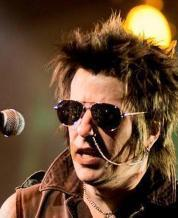

In [11]:
celeba[10][0]

Load CLIP from huggingface

In [12]:
CLIP_VERSION = "openai/clip-vit-base-patch32"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = CLIPModel.from_pretrained(CLIP_VERSION)
model = model.to(DEVICE)
model.eval()

processor = CLIPProcessor.from_pretrained(CLIP_VERSION)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Lets try to embed a few images using it

In [13]:
imgs = [celeba[idx][0] for idx in range(2)]
imgs

[<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>]

In [14]:
inputs = processor(images=imgs, return_tensors="pt")
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

inputs["pixel_values"].shape


torch.Size([2, 3, 224, 224])

In [15]:
with torch.inference_mode():
    img_embeds = model.get_image_features(pixel_values=inputs["pixel_values"])

img_embeds.shape


torch.Size([2, 512])

In [16]:
# `get_image_features` already returns the embedding tensor.
img_embeds.shape


torch.Size([2, 512])

worth L2-normalising embeds before saving so cosine similarity becomes a plain dot product later.

In [17]:
img_embeds = F.normalize(img_embeds, p=2, dim=-1)
img_embeds.shape


torch.Size([2, 512])

In [18]:
img_embeds

tensor([[ 0.0401,  0.0096, -0.0243,  ...,  0.0700,  0.0218, -0.0172],
        [ 0.0234,  0.0097, -0.0136,  ...,  0.0202, -0.0179,  0.0309]],
       device='cuda:0')

In [19]:
img_embeds[0].norm()

tensor(1., device='cuda:0')

normalization worked; vector length = 1

In [22]:
torch.save(img_embeds, src_root / "/sample_db.pt")

### Tests

In [23]:
def embed_celeba_imgs(num_imgs, batch_size=128):
    """Embed all CelebA test images using CLIP's image tower."""

    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)

        with torch.inference_mode():
            embeddings = model.get_image_features(pixel_values=pixel_values)
            embeddings = F.normalize(embeddings, p=2, dim=-1)
            batches.append(embeddings)

    return torch.cat(batches, dim=0)


In [24]:
db = embed_celeba_imgs(num_imgs=len(celeba))
db.shape

torch.Size([19962, 512])

Looks good, all 19k images embedded

In [25]:
torch.save(db, src_root / "/db.pt")

*Importing `db.pt` from drive (Optional)*

In [26]:
DEVICE = globals().get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu")


## Extending to CelebA attributes

In [27]:
# creating embedding helpers that work with the Hugging Face CLIP API

def embed_image_batch(pixel_values):
    with torch.inference_mode():
        embeddings = model.get_image_features(pixel_values=pixel_values)
    return F.normalize(embeddings, p=2, dim=-1)


def embed_text_batch(text_inputs):
    with torch.inference_mode():
        embeddings = model.get_text_features(**text_inputs)
    return F.normalize(embeddings, p=2, dim=-1)


In [28]:
def embed_images(batch_size=128):
    """Embed all CelebA test images and return the resulting tensor."""

    num_imgs = len(celeba)
    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)
        batches.append(embed_image_batch(pixel_values))

    return torch.cat(batches, dim=0)


In [29]:
print(celeba.attr_names)

['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young', '']


In [30]:
celeba.attr.shape[1], len(celeba.attr_names)

(40, 41)

there is a wierd behaviour where CelebA dataloader returns 41 attributes instead of 40. the last one is an empty string. we'll take this into account when retrieving the attributes

In [31]:
def embed_attributes():
    # Replace underscores in attribute names with spaces; CLIP was trained on natural English.
    text = [attribute.replace("_", " ") for attribute in celeba.attr_names[:40]]
    inputs = processor(text=text, return_tensors="pt", padding=True, truncation=True)
    text_inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
    return embed_text_batch(text_inputs)


In [32]:
text_db = embed_attributes()
text_db.shape

torch.Size([40, 512])

In [34]:
torch.save(text_db, src_root / "/text_db.pt")

## Exploring the evaluation data

In [46]:
annotations_path = Path(DATA_ROOT / "celeba_evaluation.json")
annotations_path.exists()

True

In [47]:
with open(annotations_path, "r") as f:
    annotations = json.load(f)

len(annotations)

14

In [48]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Notice some queries have very many reference images while others like `-Male, -Mustache` only have 27.

## Computing a baseline

we know that each query is eval file is structured like so:
```json
{
    query: "+attribute, -attribute",
    ground_truth: {
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        ...
    }
}
```
For a baseline, we can compose the query embedding by adding/subtructing attribute embeddings like so:
`q = v_ref + Σ attrtibuts⁺ − Σ attributes⁻`

we can try:
- Parse "+attribute, -attribute" into separate lists, retrive their embedding representations, sum up each list.
- For each ref image in query's ground_truth:
    - Compose q as shown above
    - Cosine similarity between q and all 19k img embeds
    - Rank in descending order, take top-K
    - Evaluate: Recall@K, Precision@K for K in {1, 5, 10}
- Average the results. maybe we can explore better aggregation techiniques later

### Experiments

In [55]:
img_db = torch.load(src_root / "db.pt")
text_db = torch.load(src_root / "text_db.pt")

img_db.to("cuda")
text_db.to("cuda")

img_db.shape, text_db.shape

/tmp/ipykernel_1835/1007488379.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  img_db = torch.load(src_root / "db.pt")
/tmp/ipykernel_1835/1007488379.py:2: FutureWarning

(torch.Size([19962, 512]), torch.Size([40, 512]))

Loading our dbs works fine

In [56]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Lets create our helper functions

In [57]:
attribute2idx = {name: idx for idx, name in enumerate(celeba.attr_names[:40])}
attribute2idx

{'5_o_Clock_Shadow': 0,
 'Arched_Eyebrows': 1,
 'Attractive': 2,
 'Bags_Under_Eyes': 3,
 'Bald': 4,
 'Bangs': 5,
 'Big_Lips': 6,
 'Big_Nose': 7,
 'Black_Hair': 8,
 'Blond_Hair': 9,
 'Blurry': 10,
 'Brown_Hair': 11,
 'Bushy_Eyebrows': 12,
 'Chubby': 13,
 'Double_Chin': 14,
 'Eyeglasses': 15,
 'Goatee': 16,
 'Gray_Hair': 17,
 'Heavy_Makeup': 18,
 'High_Cheekbones': 19,
 'Male': 20,
 'Mouth_Slightly_Open': 21,
 'Mustache': 22,
 'Narrow_Eyes': 23,
 'No_Beard': 24,
 'Oval_Face': 25,
 'Pale_Skin': 26,
 'Pointy_Nose': 27,
 'Receding_Hairline': 28,
 'Rosy_Cheeks': 29,
 'Sideburns': 30,
 'Smiling': 31,
 'Straight_Hair': 32,
 'Wavy_Hair': 33,
 'Wearing_Earrings': 34,
 'Wearing_Hat': 35,
 'Wearing_Lipstick': 36,
 'Wearing_Necklace': 37,
 'Wearing_Necktie': 38,
 'Young': 39}

In [58]:
def sum_up(attributes):
    if len(attributes) > 0:
        # retrieve their embedding representations from db
        # when we slice from db we get (512,); lets make it (1,512) using unsqueeze
        embeds = [text_db[attribute2idx[attr]].unsqueeze(0) for attr in attributes]
        # concatenete then sum up all +ve embeds, same for -ve
        result = torch.sum(torch.cat(embeds, 0), 0, keepdim=True)
        return result
    return torch.zeros((1, 512), dtype=torch.float32, device="cuda")  # empty tensor

In [59]:
from math import inf


def compute_similarity(query, db, ref_idx, k=10):
    # (19k,512)*(512,1)
    score = db @ query.T

    # modify the score of ref_img to eliminate it from top-k
    score[ref_idx] = -inf
    sorted_scores, img_idxs = torch.sort(score, dim=0, descending=True)
    top_k = (torch.flatten(img_idxs[:k])).tolist()

    # print('scores',score[:5])
    # print('-'*20)
    # print('sorted_scores',sorted_scores[:5])
    # print('-'*20)
    # print('img_idxs',img_idxs[:5])
    # print('-'*20)

    return top_k

In [60]:
def evaluate_retrieval(retrieved_indices: list[int], ground_truth_indices: list[int], k: int, log: bool = True) -> dict:
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    if log:
        print(f"retrieved={retrieved_indices[:k]}")
        print(f"truth={ground_truth_indices[:k]}")

    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {f"Recall@{k}": recall_at_k, f"Precision@{k}": precision_at_k}

In [61]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs[:1]:  # lets test for just 1 reference image
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for cutoff in [1, 5, 10]:
            result = evaluate_retrieval(top_10, ground_truths, cutoff, log=True)
            print(result)
            print("-" * 50)

In [62]:
# lets test it for just 1 iteration
for annotation in annotations[:1]:
    run_eval(annotation)

retrieved=[13877]
truth=[325]
{'Recall@1': 0, 'Precision@1': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14315, 4868, 10996]
truth=[325, 456, 579, 685, 763]
{'Recall@5': 0, 'Precision@5': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14315, 4868, 10996, 11778, 17961, 3874, 7357, 3025]
truth=[325, 456, 579, 685, 763, 893, 981, 1363, 1646, 2142]
{'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------


In [63]:
annotations[0]["query"], list(annotations[0]["ground_truth"].keys())[0]

('+Smiling', '13')

for this single iteration using the first query "+Smiling" and only 1 ref image, we get no hits. lets visually inspect the results

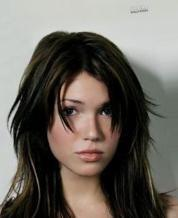

In [64]:
celeba[13][0]

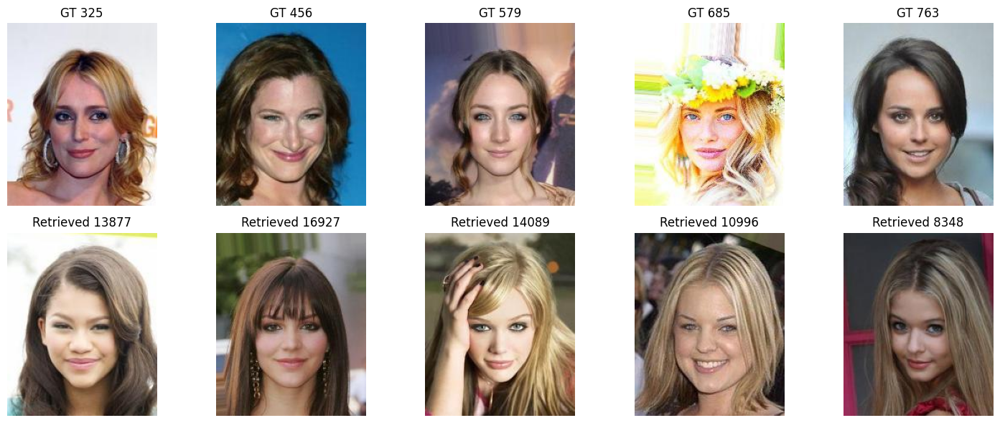

In [65]:
retrieved = [13877, 16927, 14089, 10996, 8348]
ground_truth = [325, 456, 579, 685, 763]

fig, axes = plt.subplots(2, len(retrieved), figsize=(15, 6))
for col, (gt, rt) in enumerate(zip(ground_truth, retrieved)):
    axes[0, col].imshow(celeba[gt][0])
    axes[0, col].set_title(f"GT {gt}")
    axes[0, col].axis("off")

    axes[1, col].imshow(celeba[rt][0])
    axes[1, col].set_title(f"Retrieved {rt}")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Ground truth")
axes[1, 0].set_ylabel("Retrieved")
plt.tight_layout()
plt.show()

at least all retrieved imgs are women and seem to be smiling.

The fact that none of them happen to be in the ground-truth set is expected: ground truth requires Hamming ≤ 2 on all 40 attributes, which is a much tighter constraint than just "smiling woman".

we will get more insights on perfonce by running the eval on the entire annotation set and aggregating results. lets work on the aggregation logic:

- lets start simple, we'll compute the avg of each k metric(recall, precision) for each query, across all reference imgs.
- we can track totals like so
```json
{
  "+Smiling": {"ref_counts": 50 ,"Recall@1": 0.05, "Precision@1": 0.05, "Recall@5": 0.12, ...},
  "+Eyeglasses": {"ref_counts": 1000, "Recall@1": 0.08, ...},
}
```
- then compute avg at the end using img ref counts

In [66]:
def initialize_scores():
    scores = {}
    for annotation in annotations:
        attributes = annotation["query"]
        refs = annotation["ground_truth"].keys()
        scores[attributes] = {"ref_counts": len(refs)}

        for k in [1, 5, 10]:
            recall = f"Recall@{k}"
            precision = f"Precision@{k}"
            scores[attributes][recall] = 0
            scores[attributes][precision] = 0

    return scores

In [67]:
scores = initialize_scores()
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0

In [68]:
def log(result, query, k):
    # result example: {"Recall@1": 0, "Precision@2": 0}
    recall = f"Recall@{k}"
    precision = f"Precision@{k}"

    scores[query][recall] += result[recall]
    scores[query][precision] += result[precision]

update the eval function with the new `log` function

In [69]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs:
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for k in [1, 5, 10]:
            # result struct: {"Recall@k": 0, "Precision@k": 0}
            result = evaluate_retrieval(top_10, ground_truths, k, log=False)
            log(result, annotation["query"], k)

In [70]:
# lets test it for just 1 query, all refs
for annotation in annotations[:1]:
    run_eval(annotation)

In [71]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 298,
  'Precision@1': 298.0,
  'Recall@5': 875,
  'Precision@5': 229.39999999999816,
  'Recall@10': 1240,
  'Precision@10': 192.09999999999678},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precisi

In [72]:
def compute_averages(scores):
    avg_scores = {}
    for query in scores.keys():
        avg_scores[query] = {}
        counts = scores[query]["ref_counts"]
        for k in [1, 5, 10]:
            avg_scores[query][f"Recall@{k}"] = round((scores[query][f"Recall@{k}"] / counts), 4)
            avg_scores[query][f"Precision@{k}"] = round((scores[query][f"Precision@{k}"] / counts), 4)

    return avg_scores

In [73]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0623,
  'Precision@1': 0.0623,
  'Recall@5': 0.1828,
  'Precision@5': 0.0479,
  'Recall@10': 0.2591,
  'Precision@10': 0.0401},
 '+Eyeglasses': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Heavy_Makeup': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Male': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Young': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Blond_Hair': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Mustache': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Eyegla

- for each of the 4786 ref images we used to retrieve similar embeddings from the db, only ~6.5% were the first in the list.
- Random chance would be much lower (≈ |ground truth| / 19962), so the baseline is doing better than guessing. This is strenghtened by the fact that CLIP's image embeddings already capture some attribute structure, and naïve vector arithmetic nudges the query in roughly the right direction. But it's far from accurate retrieval.
- lets test this flow using the full eval set

### Tests

In [74]:
# reset scores
scores = initialize_scores()

In [75]:
# lets run the full pipeline
for annotation in annotations:
    run_eval(annotation)

In [76]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 298,
  'Precision@1': 298.0,
  'Recall@5': 875,
  'Precision@5': 229.39999999999816,
  'Recall@10': 1240,
  'Precision@10': 192.09999999999678},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 36,
  'Precision@1': 36.0,
  'Recall@5': 161,
  'Precision@5': 37.19999999999995,
  'Recall@10': 251,
  'Precision@10': 33.600000000000094},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 117,
  'Precision@1': 117.0,
  'Recall@5': 380,
  'Precision@5': 88.00000000000054,
  'Recall@10': 578,
  'Precision@10': 73.00000000000027},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 10,
  'Precision@1': 10.0,
  'Recall@5': 22,
  'Precision@5': 5.8000000000000025,
  'Recall@10': 29,
  'Precision@10': 4.2},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 102,
  'Precision@1': 102.0,
  'Recall@5': 302,
  'Precision@5': 70.80000000000037,
  'Recall@10': 520,
  'Precision@10': 68.80000000000031},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 135,
  'Pre

In [77]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0623,
  'Precision@1': 0.0623,
  'Recall@5': 0.1828,
  'Precision@5': 0.0479,
  'Recall@10': 0.2591,
  'Precision@10': 0.0401},
 '+Eyeglasses': {'Recall@1': 0.0164,
  'Precision@1': 0.0164,
  'Recall@5': 0.0733,
  'Precision@5': 0.0169,
  'Recall@10': 0.1143,
  'Precision@10': 0.0153},
 '-Heavy_Makeup': {'Recall@1': 0.0286,
  'Precision@1': 0.0286,
  'Recall@5': 0.093,
  'Precision@5': 0.0215,
  'Recall@10': 0.1414,
  'Precision@10': 0.0179},
 '+Male': {'Recall@1': 0.0063,
  'Precision@1': 0.0063,
  'Recall@5': 0.0138,
  'Precision@5': 0.0036,
  'Recall@10': 0.0182,
  'Precision@10': 0.0026},
 '-Young': {'Recall@1': 0.019,
  'Precision@1': 0.019,
  'Recall@5': 0.0564,
  'Precision@5': 0.0132,
  'Recall@10': 0.0971,
  'Precision@10': 0.0128},
 '+Blond_Hair': {'Recall@1': 0.0247,
  'Precision@1': 0.0247,
  'Recall@5': 0.0819,
  'Precision@5': 0.0216,
  'Recall@10': 0.1267,
  'Precision@10': 0.0193},
 '+Mustache': {'Recall@1': 0.0664,
  'Precision@1': 0.0664,
 

In [78]:
def visualize_results():
    queries = list(averages.keys())
    metrics = ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    x = np.arange(len(queries))
    w = 0.13

    fig, ax = plt.subplots(figsize=(14, 6))
    for i, m in enumerate(metrics):
        ax.bar(x + i * w, [averages[q][m] for q in queries], w, label=m)

    ax.set_xticks(x + w * 2.5)
    ax.set_xticklabels(queries, rotation=45, ha="right")
    ax.set_ylabel("Score")
    ax.legend()
    plt.tight_layout()
    plt.show()

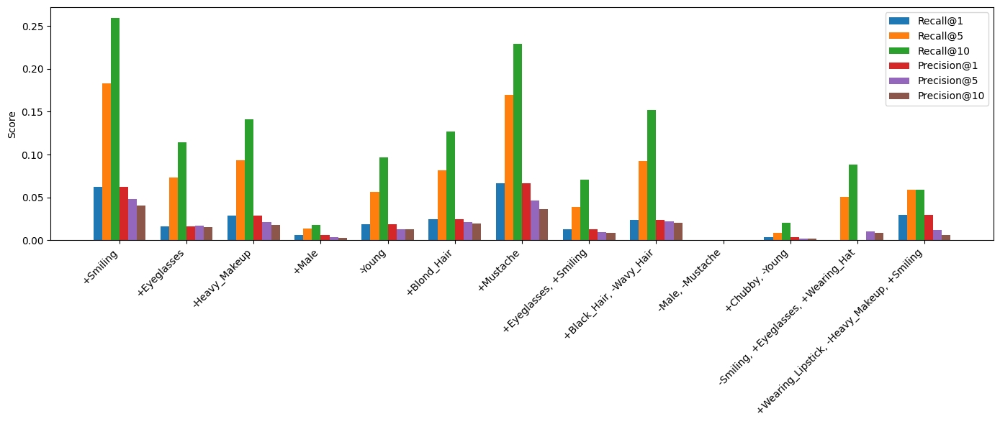

In [79]:
visualize_results()

- `-Male, -Mustache`: 0 hits across the board. small gt pool (27 src imgs)? or double -ve breaking the arithmetic? or both attrs pushing same direction (redundancy)?
- `+Mustache` vs `+Male`: both signal masculine features but mustache does way better. why?
- `+Chubby, -Young`: near zero. rare attribute + negative combo. how often does it actually appear in data?
- precision values tiny across the board (<0.07). large gt lists explain some of it, but possibly also a sign naive composition is fundamentally weak
- single +ve attrs outperform multi-attr queries. stacking conditions breaks naive arithmetic. this is exactly what threads 2 & 4 should fix

# **Thread 2 - GDE-style Geodesic Composition**




**0. Getting everything ready for Thread 2**

In [80]:
# Thread 2 minimal setup: reuse baseline objects instead of rebuilding them.

from pathlib import Path
from typing import Dict, List, Tuple

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_ROOT = globals().get("data_root", Path("../data"))
SRC_ROOT = Path("../src")
THREAD2_DIR = Path("../results/thread_2")
CACHE_DIR = THREAD2_DIR / "cache"

THREAD2_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

EVAL_PATH = DATA_ROOT / "celeba_evaluation.json"
DB_PATH = SRC_ROOT / "db.pt"
DIRECTIONS_CACHE_PATH = CACHE_DIR / "gde_attribute_directions.pt"
IMG_DIR = DATA_ROOT / "celeba" / "img_align_celeba"

# Check that the baseline section was run.
required_baseline_objects = ["celeba", "model", "processor"]
missing = [name for name in required_baseline_objects if name not in globals()]

if missing:
    raise RuntimeError(
        "Thread 2 expects the baseline section to be run first. "
        f"Missing objects: {missing}"
    )

# Reuse baseline annotations when available. Fallback only loads the JSON if needed.
if "annotations" not in globals():
    if not EVAL_PATH.exists():
        raise FileNotFoundError(f"Could not find evaluation JSON at: {EVAL_PATH}")
    with open(EVAL_PATH, "r") as f:
        annotations = json.load(f)

# Reuse the baseline image database.
if "img_db" not in globals():
    if "db" in globals():
        img_db = db
    elif DB_PATH.exists():
        img_db = torch.load(DB_PATH, map_location="cpu")
    else:
        raise FileNotFoundError(
            "Could not find precomputed image embeddings. "
            "Run the baseline embedding section first or make sure src/db.pt exists."
        )

# Move model and image database to the active device.
model = model.to(DEVICE)
model.eval()
img_db = F.normalize(img_db.float(), p=2, dim=-1).to(DEVICE)

print("Thread 2 setup ready.")
print("DEVICE:", DEVICE)
print("DATA_ROOT:", DATA_ROOT)
print("SRC_ROOT:", SRC_ROOT)
print("THREAD2_DIR:", THREAD2_DIR)
print("CelebA test images:", len(celeba))
print("Evaluation query groups:", len(annotations))
print("Image database shape:", tuple(img_db.shape))


Thread 2 setup ready.
DEVICE: cuda
DATA_ROOT: data
SRC_ROOT: ../src
THREAD2_DIR: ../results/thread_2
CelebA test images: 19962
Evaluation query groups: 14
Image database shape: (19962, 512)


**1. Thread 2 configuration**

In [81]:
CLIP_VERSION = globals().get("CLIP_VERSION", "openai/clip-vit-base-patch32")

# Only directions are built in Thread 2. Image embeddings come from the baseline.
FORCE_REBUILD_DIRECTIONS = False

# GDE composition strength. These values are selected using the validation split.
ALPHA = 0.35
ALPHA_VALUES = [0.05, 0.1, 0.2, 0.35, 0.5]

# rho = 0.0 means pure Thread 2 GDE.
# rho > 0.0 means identity-preserving hybrid retrieval.
RHO_VALUES = [0.0, 0.5, 0.7, 0.8, 0.9]

TEXT_PROB_TAU = 0.03

# "hard"       = CelebA labels only
# "clip_soft"  = CLIP image-to-text probabilities only
# "hybrid"     = CelebA labels weighted by CLIP confidence
DIRECTION_MODE = "hybrid"

NORMALIZE_ATTRIBUTE_DIRECTIONS = True

GLOBAL_MEAN_MAX_ITER = 30
ATTR_MEAN_MAX_ITER = 10
MEAN_TOL = 1e-6

# "hit" means Recall@K is 1 if at least one ground-truth image appears in top K.
# This is really Hit@K, but the column is kept as Recall@K for project compatibility.
RECALL_MODE = "hit"

# Hyperparameter split.
# alpha/rho are selected on validation_annotations.
# final report numbers are computed on report_annotations.
VALIDATION_FRACTION = 0.20
SPLIT_SEED = 42

print("ALPHA_VALUES:", ALPHA_VALUES)
print("RHO_VALUES:", RHO_VALUES)
print("DIRECTION_MODE:", DIRECTION_MODE)
print("RECALL_MODE:", RECALL_MODE)
print("VALIDATION_FRACTION:", VALIDATION_FRACTION)
print("SPLIT_SEED:", SPLIT_SEED)


ALPHA_VALUES: [0.05, 0.1, 0.2, 0.35, 0.5]
RHO_VALUES: [0.0, 0.5, 0.7, 0.8, 0.9]
DIRECTION_MODE: hybrid
RECALL_MODE: hit
VALIDATION_FRACTION: 0.2
SPLIT_SEED: 42


**2. Create validation/report split from baseline annotations**

In [82]:
for ann in annotations:
    print(f"{ann['query']:45s} | references: {len(ann['ground_truth'])}")


def make_annotation_subset(ann: Dict, selected_ref_keys: List[str], source_annotation_id: int) -> Dict:
    """
    Create a copy of one annotation group using only selected reference IDs.
    """
    return {
        "query": ann["query"],
        "ground_truth": {str(k): ann["ground_truth"][str(k)] for k in selected_ref_keys},
        "source_annotation_id": source_annotation_id,
    }


def split_annotations_by_reference(
    annotations: List[Dict],
    validation_fraction: float = VALIDATION_FRACTION,
    seed: int = SPLIT_SEED,
) -> Tuple[List[Dict], List[Dict]]:
    """
    Split each query group's reference images into validation and report subsets.

    validation_annotations:
        used only for selecting alpha/rho.

    report_annotations:
        used for final Thread 2 numbers.
    """
    rng = np.random.default_rng(seed)

    validation_annotations = []
    report_annotations = []

    for ann_id, ann in enumerate(annotations):
        ref_keys = np.array(list(ann["ground_truth"].keys()), dtype=str)
        n = len(ref_keys)

        if n == 0:
            continue

        shuffled = ref_keys.copy()
        rng.shuffle(shuffled)

        if n == 1:
            n_val = 0
        else:
            n_val = int(round(n * validation_fraction))
            n_val = max(1, min(n_val, n - 1))

        val_keys = sorted(shuffled[:n_val].tolist(), key=lambda x: int(x))
        report_keys = sorted(shuffled[n_val:].tolist(), key=lambda x: int(x))

        if len(val_keys) > 0:
            validation_annotations.append(make_annotation_subset(ann, val_keys, ann_id))

        if len(report_keys) > 0:
            report_annotations.append(make_annotation_subset(ann, report_keys, ann_id))

    return validation_annotations, report_annotations


validation_annotations, report_annotations = split_annotations_by_reference(annotations)

print("\nSplit summary")
print("Validation query groups:", len(validation_annotations))
print("Report query groups:", len(report_annotations))
print("Validation references:", sum(len(a["ground_truth"]) for a in validation_annotations))
print("Report references:", sum(len(a["ground_truth"]) for a in report_annotations))

query_counts = pd.Series([ann["query"] for ann in annotations]).value_counts()
duplicate_queries = query_counts[query_counts > 1]

if len(duplicate_queries) > 0:
    print("\nDuplicate query strings detected. They will be aggregated correctly:")
    print(duplicate_queries.to_string())


+Smiling                                      | references: 4786
+Eyeglasses                                   | references: 2196
-Heavy_Makeup                                 | references: 4087
+Male                                         | references: 1595
-Young                                        | references: 5355
+Blond_Hair                                   | references: 5469
+Mustache                                     | references: 301
-Young                                        | references: 5355
+Eyeglasses, +Smiling                         | references: 612
+Black_Hair, -Wavy_Hair                       | references: 2572
-Male, -Mustache                              | references: 27
+Chubby, -Young                               | references: 584
-Smiling, +Eyeglasses, +Wearing_Hat           | references: 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling    | references: 34

Split summary
Validation query groups: 14
Report query groups: 14
Validation references: 6609
Repo

**3. Thread 2 CLIP/text helper utilities**

These helpers reuse the CLIP model and processor loaded by the baseline. They do **not** re-embed the CelebA image database.

In [83]:
def get_clip_tensor(output):
    """Handle both old and new Hugging Face CLIP output formats."""
    if isinstance(output, torch.Tensor):
        return output
    if hasattr(output, "pooler_output"):
        return output.pooler_output
    if hasattr(output, "last_hidden_state"):
        return output.last_hidden_state[:, 0]
    raise TypeError(f"Unsupported CLIP output type: {type(output)}")


def normalize(x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """L2-normalize vectors along the last dimension."""
    return x / x.norm(dim=-1, keepdim=True).clamp_min(eps)


@torch.inference_mode()
def embed_texts(texts: List[str]) -> torch.Tensor:
    """
    Encode text prompts with the baseline CLIP text tower.

    This is used only for Thread 2 CLIP-based denoising of attribute directions.
    It does not repeat the baseline attribute embedding database.
    """
    inputs = processor(text=texts, return_tensors="pt", padding=True, truncation=True)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    features = model.get_text_features(**inputs)
    features = get_clip_tensor(features).float()
    return normalize(features)


**4. Unit-sphere manifold utilities**

In [84]:
def safe_acos(x: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    """Numerically stable arccos for dot products."""
    return torch.acos(x.clamp(-1.0 + eps, 1.0 - eps))


def log_map(base: torch.Tensor, x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Logarithm map on the unit hypersphere.

    base: shape [D] or [1, D]
    x:    shape [D] or [N, D]
    returns tangent vector(s) at base.
    """
    base = normalize(base)
    x = normalize(x)

    single_input = False
    if x.dim() == 1:
        x = x.unsqueeze(0)
        single_input = True
    if base.dim() == 1:
        base = base.unsqueeze(0)

    dot = (x * base).sum(dim=-1, keepdim=True)
    theta = safe_acos(dot)
    sin_theta = torch.sin(theta).clamp_min(eps)
    tangent = (theta / sin_theta) * (x - dot * base)
    tangent = torch.where(theta < 1e-5, torch.zeros_like(tangent), tangent)
    return tangent.squeeze(0) if single_input else tangent


def exp_map(base: torch.Tensor, u: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Exponential map on the unit hypersphere.

    base: shape [D] or [1, D]
    u:    shape [D] or [N, D]
    returns point(s) on the sphere.
    """
    base = normalize(base)

    single_input = False
    if u.dim() == 1:
        u = u.unsqueeze(0)
        single_input = True
    if base.dim() == 1:
        base = base.unsqueeze(0)

    norm_u = u.norm(dim=-1, keepdim=True).clamp_min(eps)
    direction = u / norm_u
    y = torch.cos(norm_u) * base + torch.sin(norm_u) * direction
    y = torch.where(norm_u < 1e-5, base.expand_as(y), y)
    y = normalize(y)
    return y.squeeze(0) if single_input else y


def geodesic_distance(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Angular distance between normalized vectors on the sphere."""
    a = normalize(a)
    b = normalize(b)
    return safe_acos((a * b).sum(dim=-1))


def intrinsic_mean(
    points: torch.Tensor,
    weights: Optional[torch.Tensor] = None,
    max_iter: int = GLOBAL_MEAN_MAX_ITER,
    tol: float = MEAN_TOL,
) -> torch.Tensor:
    """
    Compute the Karcher/intrinsic mean on the unit sphere.

    points: [N, D]
    weights: optional [N] non-negative weights
    returns: [D] normalized mean point
    """
    points = normalize(points).to(DEVICE)
    n = points.shape[0]

    if weights is None:
        weights = torch.ones(n, device=points.device, dtype=points.dtype) / n
    else:
        weights = weights.to(points.device, dtype=points.dtype).flatten().clamp_min(0)
        weights = weights / weights.sum().clamp_min(1e-8)

    mu = normalize((points * weights[:, None]).sum(dim=0))

    for _ in range(max_iter):
        tangents = log_map(mu, points)
        avg_tangent = (tangents * weights[:, None]).sum(dim=0)
        step = avg_tangent.norm().item()
        mu = exp_map(mu, avg_tangent)
        if step < tol:
            break

    return normalize(mu)

**5. Quick sanity test for log/exp maps**

In [85]:
with torch.no_grad():
    p = img_db[0]
    x = img_db[1]
    x_reconstructed = exp_map(p, log_map(p, x))
    reconstruction_error = (x - x_reconstructed).norm().item()
    reconstructed_norm = x_reconstructed.norm().item()

print("Reconstruction error:", reconstruction_error)
print("Reconstructed norm:", reconstructed_norm)


Reconstruction error: 3.515551227906144e-08
Reconstructed norm: 1.0


**6. Prompt templates for CLIP denoising**

In [86]:
def attr_to_phrase(attr: str) -> str:
    """Convert CelebA attribute name to a natural phrase."""
    return attr.replace("_", " ").lower()


def positive_negative_prompts(attr: str) -> Tuple[List[str], List[str]]:
    """Return positive and negative text prompts for one CelebA attribute."""
    phrase = attr_to_phrase(attr)

    special = {
        "Male": (
            ["a photo of a male person", "a portrait of a man", "a face of a male person"],
            ["a photo of a female person", "a portrait of a woman", "a face of a female person"],
        ),
        "Young": (
            ["a photo of a young person", "a portrait of a young face", "a young looking face"],
            ["a photo of an old person", "a portrait of an older face", "an elderly looking face"],
        ),
        "Smiling": (
            ["a photo of a smiling person", "a face with a smile", "a person who is smiling"],
            ["a photo of a person not smiling", "a neutral face", "a face without a smile"],
        ),
        "Eyeglasses": (
            ["a person wearing eyeglasses", "a face with glasses", "a portrait with eyeglasses"],
            ["a person without eyeglasses", "a face without glasses", "a portrait without eyeglasses"],
        ),
        "Heavy_Makeup": (
            ["a person wearing heavy makeup", "a face with heavy makeup", "a portrait with heavy makeup"],
            ["a person without heavy makeup", "a natural face without makeup", "a portrait without heavy makeup"],
        ),
        "Wearing_Lipstick": (
            ["a person wearing lipstick", "a face with lipstick", "a portrait with lipstick"],
            ["a person without lipstick", "a face without lipstick", "a portrait without lipstick"],
        ),
        "Wearing_Hat": (
            ["a person wearing a hat", "a face with a hat", "a portrait with a hat"],
            ["a person without a hat", "a face without a hat", "a portrait without a hat"],
        ),
        "Mustache": (
            ["a person with a mustache", "a face with a mustache", "a portrait with a mustache"],
            ["a person without a mustache", "a face without a mustache", "a portrait without a mustache"],
        ),
        "Chubby": (
            ["a chubby face", "a person with a chubby face", "a round face"],
            ["a slim face", "a person with a thin face", "a narrow face"],
        ),
    }

    if attr in special:
        return special[attr]

    if attr.endswith("_Hair"):
        return (
            [f"a person with {phrase}", f"a face with {phrase}", f"a portrait of a person with {phrase}"],
            [f"a person without {phrase}", f"a face without {phrase}", f"a portrait without {phrase}"],
        )

    if attr.startswith("Wearing_"):
        item = phrase.replace("wearing ", "")
        return (
            [f"a person wearing {item}", f"a face with {item}", f"a portrait with {item}"],
            [f"a person not wearing {item}", f"a face without {item}", f"a portrait without {item}"],
        )

    return (
        [f"a face with {phrase}", f"a person with {phrase}", f"a portrait of a person with {phrase}"],
        [f"a face without {phrase}", f"a person without {phrase}", f"a portrait without {phrase}"],
    )


@torch.inference_mode()
def clip_attribute_probability(attr: str, img_db: torch.Tensor, tau: float = TEXT_PROB_TAU) -> torch.Tensor:
    """
    Compute soft CLIP probability that each image has the attribute.

    Returns:
        p_pos: tensor [N], where high value means CLIP thinks the image has attr.
    """
    pos_prompts, neg_prompts = positive_negative_prompts(attr)
    pos_emb = embed_texts(pos_prompts)
    neg_emb = embed_texts(neg_prompts)

    pos_score = (img_db @ pos_emb.T).mean(dim=1)
    neg_score = (img_db @ neg_emb.T).mean(dim=1)

    logits = torch.stack([neg_score, pos_score], dim=1) / tau
    p_pos = torch.softmax(logits, dim=1)[:, 1]
    return p_pos.detach()


**7. Build image-derived attribute directions**

In [87]:
def get_attr_labels(attr: str) -> torch.Tensor:
    """
    Return boolean labels for one CelebA attribute in the test split.
    """
    attr_names = list(celeba.attr_names[:40])
    attr2idx = {a: i for i, a in enumerate(attr_names)}

    if attr not in attr2idx:
        raise KeyError(f"Unknown attribute {attr}. Available attributes: {attr_names}")

    labels = torch.as_tensor(celeba.attr[:, attr2idx[attr]])
    return labels > 0


def current_direction_config() -> Dict:
    """
    Metadata used to check whether the cached GDE directions are still valid.
    """
    return {
        "clip_version": CLIP_VERSION,
        "num_images": int(len(celeba)),
        "embedding_dim": int(img_db.shape[1]),
        "direction_mode": DIRECTION_MODE,
        "text_prob_tau": float(TEXT_PROB_TAU),
        "normalize_attribute_directions": bool(NORMALIZE_ATTRIBUTE_DIRECTIONS),
        "global_mean_max_iter": int(GLOBAL_MEAN_MAX_ITER),
        "attr_mean_max_iter": int(ATTR_MEAN_MAX_ITER),
        "attr_names": list(celeba.attr_names[:40]),
    }


def cache_matches_config(cache: Dict) -> bool:
    """
    Return True only when the cached directions match the current settings.
    """
    expected = current_direction_config()
    cached = cache.get("config", {})

    if not cached:
        cached = {
            "direction_mode": cache.get("direction_mode"),
            "text_prob_tau": cache.get("text_prob_tau"),
            "normalize_attribute_directions": cache.get("normalize_attribute_directions"),
            "attr_names": cache.get("attr_names"),
        }

    mismatches = []

    for key, expected_value in expected.items():
        cached_value = cached.get(key, None)
        if cached_value != expected_value:
            mismatches.append((key, cached_value, expected_value))

    if mismatches:
        print("Cached directions do not match current config. Rebuilding...")
        for key, old, new in mismatches:
            print(f"  {key}: cached={old} | current={new}")
        return False

    return True


def build_one_attribute_direction(attr: str, mu: torch.Tensor) -> torch.Tensor:
    """
    Build one image-derived GDE primitive direction for one CelebA attribute.
    """
    labels = get_attr_labels(attr).to(DEVICE)
    labels_float = labels.float()

    if DIRECTION_MODE == "hard":
        pos_weights = labels_float
        neg_weights = 1.0 - labels_float

    elif DIRECTION_MODE == "clip_soft":
        p_pos = clip_attribute_probability(attr, img_db)
        pos_weights = p_pos
        neg_weights = 1.0 - p_pos

    elif DIRECTION_MODE == "hybrid":
        p_pos = clip_attribute_probability(attr, img_db)

        pos_weights = labels_float * p_pos
        neg_weights = (1.0 - labels_float) * (1.0 - p_pos)

    else:
        raise ValueError("DIRECTION_MODE must be 'hard', 'clip_soft', or 'hybrid'.")

    pos_weights = pos_weights.clamp_min(1e-8)
    neg_weights = neg_weights.clamp_min(1e-8)

    pos_mean = intrinsic_mean(img_db, weights=pos_weights, max_iter=ATTR_MEAN_MAX_ITER)
    neg_mean = intrinsic_mean(img_db, weights=neg_weights, max_iter=ATTR_MEAN_MAX_ITER)

    direction = log_map(mu, pos_mean) - log_map(mu, neg_mean)

    if NORMALIZE_ATTRIBUTE_DIRECTIONS:
        direction = direction / direction.norm().clamp_min(1e-8)

    return direction.detach()


def build_all_attribute_directions(force_rebuild: bool = FORCE_REBUILD_DIRECTIONS) -> Dict:
    """
    Build or load all Thread 2 image-derived attribute directions.
    """
    if DIRECTIONS_CACHE_PATH.exists() and not force_rebuild:
        cache = torch.load(DIRECTIONS_CACHE_PATH, map_location=DEVICE)

        if cache_matches_config(cache):
            cache["mu"] = cache["mu"].to(DEVICE)
            cache["directions"] = {k: v.to(DEVICE) for k, v in cache["directions"].items()}
            print(f"Loaded cached directions from {DIRECTIONS_CACHE_PATH}")
            return cache

    attr_names = list(celeba.attr_names[:40])

    print("Computing global intrinsic mean of image database...")
    mu = intrinsic_mean(img_db, max_iter=GLOBAL_MEAN_MAX_ITER)

    directions = {}

    print("Building image-derived GDE directions...")
    for attr in tqdm(attr_names):
        directions[attr] = build_one_attribute_direction(attr, mu)

    cache = {
        "mu": mu.detach().cpu(),
        "directions": {k: v.detach().cpu() for k, v in directions.items()},
        "attr_names": attr_names,
        "alpha_default": ALPHA,
        "direction_mode": DIRECTION_MODE,
        "text_prob_tau": TEXT_PROB_TAU,
        "normalize_attribute_directions": NORMALIZE_ATTRIBUTE_DIRECTIONS,
        "config": current_direction_config(),
    }

    torch.save(cache, DIRECTIONS_CACHE_PATH)
    print(f"Saved directions to {DIRECTIONS_CACHE_PATH}")

    cache["mu"] = cache["mu"].to(DEVICE)
    cache["directions"] = {k: v.to(DEVICE) for k, v in cache["directions"].items()}

    return cache

**8. Compute or load Thread 2 directions**

In [88]:
cache = build_all_attribute_directions(force_rebuild=FORCE_REBUILD_DIRECTIONS)
mu = cache["mu"]
directions = cache["directions"]

print("Global mean shape:", tuple(mu.shape))
print("Number of directions:", len(directions))
print("Example direction norm for Smiling:", directions["Smiling"].norm().item())


Computing global intrinsic mean of image database...
Building image-derived GDE directions...


  0%|          | 0/40 [00:00<?, ?it/s]

Saved directions to ../results/thread_2/cache/gde_attribute_directions.pt
Global mean shape: (512,)
Number of directions: 40
Example direction norm for Smiling: 0.9999999403953552


**9. Query parsing and GDE query composition**

In [89]:
def parse_query(query: str) -> Tuple[List[str], List[str]]:
    """Example: '+Smiling, -Eyeglasses' -> ['Smiling'], ['Eyeglasses']."""
    positive, negative = [], []
    parts = [p.strip() for p in query.split(",") if p.strip()]
    for part in parts:
        sign, attr = part[0], part[1:]
        if sign == "+":
            positive.append(attr)
        elif sign == "-":
            negative.append(attr)
        else:
            raise ValueError(f"Query part must start with + or -: {part}")
    return positive, negative


def compose_gde_query(
    ref_embedding: torch.Tensor,
    positive_attrs: Iterable[str],
    negative_attrs: Iterable[str],
    alpha: float = ALPHA,
) -> torch.Tensor:
    """Compose a Thread 2 GDE query on the unit sphere."""
    ref_embedding = normalize(ref_embedding.to(DEVICE))
    z_ref = log_map(mu, ref_embedding)
    edit = torch.zeros_like(z_ref)

    for attr in positive_attrs:
        edit = edit + directions[attr]
    for attr in negative_attrs:
        edit = edit - directions[attr]

    z_query = z_ref + alpha * edit
    q = exp_map(mu, z_query)
    return normalize(q)


**10. Retrieval and metrics**

In [90]:
def retrieve_topk(query_embedding: torch.Tensor, ref_idx: int, k: int = 10) -> List[int]:
    """
    Retrieve top-k image indices by cosine similarity to the composed query only.
    """
    query_embedding = normalize(query_embedding).to(DEVICE)

    scores = img_db @ query_embedding
    scores = scores.clone()
    scores[ref_idx] = -float("inf")

    return torch.topk(scores, k=k, largest=True).indices.detach().cpu().tolist()


def evaluate_retrieval(
    retrieved_indices: List[int],
    ground_truth_indices: List[int],
    k: int,
    recall_mode: str = RECALL_MODE,
) -> Dict[str, float]:
    """
    Evaluate one reference image at cutoff K.
    """
    top_k = retrieved_indices[:k]

    gt = [int(x) for x in ground_truth_indices]
    hits = len(set(top_k).intersection(set(gt)))

    precision = hits / k

    if recall_mode == "hit":
        recall = 1.0 if hits > 0 else 0.0

    elif recall_mode == "true":
        recall = hits / max(len(gt), 1)

    else:
        raise ValueError("recall_mode must be 'hit' or 'true'.")

    return {
        f"Recall@{k}": recall,
        f"Precision@{k}": precision,
    }


def initialize_scores(eval_annotations: List[Dict]) -> Dict:
    """
    Create a score accumulator.

    Important:
    duplicate query strings, such as '-Young', are aggregated by increasing
    ref_counts instead of overwriting the previous row.
    """
    scores = {}

    for ann in eval_annotations:
        query = ann["query"]

        if query not in scores:
            scores[query] = {"ref_counts": 0}

            for k in [1, 5, 10]:
                scores[query][f"Recall@{k}"] = 0.0
                scores[query][f"Precision@{k}"] = 0.0

        scores[query]["ref_counts"] += len(ann["ground_truth"])

    return scores


def compute_averages(scores: Dict) -> pd.DataFrame:
    """
    Convert accumulated scores into a per-query DataFrame.
    """
    rows = []

    for query, values in scores.items():
        count = int(values["ref_counts"])

        if count == 0:
            continue

        row = {
            "query": query,
            "ref_counts": count,
        }

        for k in [1, 5, 10]:
            row[f"Recall@{k}"] = round(values[f"Recall@{k}"] / count, 4)
            row[f"Precision@{k}"] = round(values[f"Precision@{k}"] / count, 4)

        rows.append(row)

    return pd.DataFrame(rows).sort_values("query").reset_index(drop=True)


def macro_summary(df: pd.DataFrame) -> Dict[str, float]:
    """
    Return macro averages over query rows.
    """
    return {
        "Macro_Recall@1": float(df["Recall@1"].mean()),
        "Macro_Precision@1": float(df["Precision@1"].mean()),
        "Macro_Recall@5": float(df["Recall@5"].mean()),
        "Macro_Precision@5": float(df["Precision@5"].mean()),
        "Macro_Recall@10": float(df["Recall@10"].mean()),
        "Macro_Precision@10": float(df["Precision@10"].mean()),
    }

**11. Run Thread 2 evaluations**

In [91]:
def retrieve_topk_hybrid(
    query_embedding: torch.Tensor,
    ref_embedding: torch.Tensor,
    ref_idx: int,
    k: int = 10,
    rho: float = 0.0,
) -> List[int]:
    """
    Retrieve top-k images.

    rho = 0.0:
        pure Thread 2 GDE retrieval.

    rho > 0.0:
        identity-preserving hybrid retrieval:
        score = rho * sim(database, reference) + (1-rho) * sim(database, composed_query)
    """
    query_embedding = normalize(query_embedding).to(DEVICE)
    ref_embedding = normalize(ref_embedding).to(DEVICE)

    edit_scores = img_db @ query_embedding

    if rho == 0.0:
        scores = edit_scores
    else:
        identity_scores = img_db @ ref_embedding
        scores = rho * identity_scores + (1.0 - rho) * edit_scores

    scores = scores.clone()
    scores[ref_idx] = -float("inf")

    return torch.topk(scores, k=k, largest=True).indices.detach().cpu().tolist()


def run_thread2_eval_alpha_rho(
    alpha: float,
    rho: float,
    eval_annotations: List[Dict],
    recall_mode: str = RECALL_MODE,
    desc_prefix: str = "",
) -> pd.DataFrame:
    """
    Run Thread 2 evaluation for a selected alpha/rho on a selected annotation split.
    """
    scores = initialize_scores(eval_annotations)

    desc = f"{desc_prefix} alpha={alpha}, rho={rho}".strip()

    for ann in tqdm(eval_annotations, desc=desc, leave=False):
        pos_attrs, neg_attrs = parse_query(ann["query"])
        ref_indices = [int(x) for x in ann["ground_truth"].keys()]

        for ref_idx in ref_indices:
            ref_embedding = img_db[ref_idx]

            q = compose_gde_query(
                ref_embedding=ref_embedding,
                positive_attrs=pos_attrs,
                negative_attrs=neg_attrs,
                alpha=alpha,
            )

            top10 = retrieve_topk_hybrid(
                query_embedding=q,
                ref_embedding=ref_embedding,
                ref_idx=ref_idx,
                k=10,
                rho=rho,
            )

            gt = ann["ground_truth"][str(ref_idx)]

            for k in [1, 5, 10]:
                result = evaluate_retrieval(top10, gt, k, recall_mode=recall_mode)

                scores[ann["query"]][f"Recall@{k}"] += result[f"Recall@{k}"]
                scores[ann["query"]][f"Precision@{k}"] += result[f"Precision@{k}"]

    return compute_averages(scores)


all_validation_summaries = []
all_validation_results = {}

for alpha in ALPHA_VALUES:
    for rho in RHO_VALUES:
        df = run_thread2_eval_alpha_rho(
            alpha=alpha,
            rho=rho,
            eval_annotations=validation_annotations,
            recall_mode=RECALL_MODE,
            desc_prefix="VALIDATION",
        )

        all_validation_results[(alpha, rho)] = df

        row = {
            "alpha": alpha,
            "rho": rho,
            "split": "validation",
            **macro_summary(df),
        }

        all_validation_summaries.append(row)

validation_grid_df = pd.DataFrame(all_validation_summaries)

validation_grid_df = validation_grid_df.sort_values(
    by=["Macro_Recall@10", "Macro_Precision@10"],
    ascending=False,
).reset_index(drop=True)

best_alpha = float(validation_grid_df.loc[0, "alpha"])
best_rho = float(validation_grid_df.loc[0, "rho"])

pure_grid_df = validation_grid_df[validation_grid_df["rho"] == 0.0].copy()

pure_grid_df = pure_grid_df.sort_values(
    by=["Macro_Recall@10", "Macro_Precision@10"],
    ascending=False,
).reset_index(drop=True)

best_pure_alpha = float(pure_grid_df.loc[0, "alpha"])
best_pure_rho = 0.0

print("Best validation config:")
print("  best_alpha:", best_alpha)
print("  best_rho:", best_rho)

print("\nBest pure-GDE validation config:")
print("  best_pure_alpha:", best_pure_alpha)
print("  best_pure_rho:", best_pure_rho)

display(validation_grid_df)

best_results_report_df = run_thread2_eval_alpha_rho(
    alpha=best_alpha,
    rho=best_rho,
    eval_annotations=report_annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="REPORT BEST",
)

pure_results_report_df = run_thread2_eval_alpha_rho(
    alpha=best_pure_alpha,
    rho=best_pure_rho,
    eval_annotations=report_annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="REPORT PURE-GDE",
)

best_results_all_df = run_thread2_eval_alpha_rho(
    alpha=best_alpha,
    rho=best_rho,
    eval_annotations=annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="ALL BEST",
)

pure_results_all_df = run_thread2_eval_alpha_rho(
    alpha=best_pure_alpha,
    rho=best_pure_rho,
    eval_annotations=annotations,
    recall_mode=RECALL_MODE,
    desc_prefix="ALL PURE-GDE",
)

# Backward-compatible names for later cells.
grid_df = validation_grid_df
best_results_df = best_results_report_df

print("\nHeld-out report results: best hybrid")
display(best_results_report_df)
print(macro_summary(best_results_report_df))

print("\nHeld-out report results: pure GDE ablation")
display(pure_results_report_df)
print(macro_summary(pure_results_report_df))

print("\nFull mandatory-list results with validation-selected config")
display(best_results_all_df)
print(macro_summary(best_results_all_df))

VALIDATION alpha=0.05, rho=0.0:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.5:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.7:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.8:   0%|          | 0/14 [00:00<?, ?it/s]

VALIDATION alpha=0.05, rho=0.9:   0%|          | 0/14 [00:00<?, ?it/s]

...

{'Macro_Recall@1': 0.0360076923076923, 'Macro_Precision@1': 0.0360076923076923, 'Macro_Recall@5': 0.10733846153846155, 'Macro_Precision@5': 0.026261538461538465, 'Macro_Recall@10': 0.1546076923076923, 'Macro_Precision@10': 0.02130769230769231}

Held-out report results: pure GDE ablation


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10
0,"+Black_Hair, -Wavy_Hair",2058,0.0083,0.0083,0.0335,0.0083,0.0603,0.0079
1,+Blond_Hair,4375,0.0370,0.0370,0.1291,0.0332,0.2002,0.0302
2,"+Chubby, -Young",467,0.0128,0.0128,0.0343,0.0073,0.0685,0.0077
3,+Eyeglasses,1757,0.0250,0.0250,0.1104,0.0261,0.1696,0.0224
4,"+Eyeglasses, +Smiling",490,0.0163,0.0163,0.0796,0.0171,0.1122,0.0137
5,+Male,1276,0.0400,0.0400,0.1442,0.0381,0.2249,0.0350
6,+Mustache,241,0.0664,0.0664,0.1577,0.0456,0.2241,0.0353
7,+Smiling,3829,0.0658,0.0658,0.1781,0.0481,0.2442,0.0396
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",27,0.0370,0.0370,0.0741,0.0148,0.0741,0.0074
9,-Heavy_Makeup,3270,0.0312,0.0312,0.0798,0.0193,0.1141,0.0149


{'Macro_Recall@1': 0.0360076923076923, 'Macro_Precision@1': 0.0360076923076923, 'Macro_Recall@5': 0.10733846153846155, 'Macro_Precision@5': 0.026261538461538465, 'Macro_Recall@10': 0.1546076923076923, 'Macro_Precision@10': 0.02130769230769231}

Full mandatory-list results with validation-selected config


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10
0,"+Black_Hair, -Wavy_Hair",2572,0.0089,0.0089,0.0342,0.0082,0.0610,0.0079
1,+Blond_Hair,5469,0.0382,0.0382,0.1307,0.0338,0.1997,0.0304
2,"+Chubby, -Young",584,0.0103,0.0103,0.0360,0.0075,0.0736,0.0080
3,+Eyeglasses,2196,0.0287,0.0287,0.1166,0.0270,0.1749,0.0231
4,"+Eyeglasses, +Smiling",612,0.0147,0.0147,0.0686,0.0147,0.0964,0.0116
5,+Male,1595,0.0420,0.0420,0.1511,0.0397,0.2270,0.0355
6,+Mustache,301,0.0731,0.0731,0.1661,0.0472,0.2359,0.0369
7,+Smiling,4786,0.0662,0.0662,0.1763,0.0477,0.2409,0.0392
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",34,0.0294,0.0294,0.0588,0.0118,0.0882,0.0088
9,-Heavy_Makeup,4087,0.0299,0.0299,0.0798,0.0191,0.1167,0.0152


{'Macro_Recall@1': 0.037338461538461536, 'Macro_Precision@1': 0.037338461538461536, 'Macro_Recall@5': 0.1073076923076923, 'Macro_Precision@5': 0.026115384615384617, 'Macro_Recall@10': 0.15791538461538462, 'Macro_Precision@10': 0.021861538461538464}


**12. Save the results**

In [92]:
VALIDATION_GRID_PATH = THREAD2_DIR / "thread2_validation_alpha_rho_grid_summary.csv"
BEST_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_best_report_results.csv"
PURE_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_pure_gde_report_results.csv"
BEST_ALL_RESULTS_PATH = THREAD2_DIR / "thread2_best_all_results.csv"
PURE_ALL_RESULTS_PATH = THREAD2_DIR / "thread2_pure_gde_all_results.csv"
BEST_CONFIG_PATH = THREAD2_DIR / "thread2_best_config.json"
SPLIT_INFO_PATH = THREAD2_DIR / "thread2_validation_report_split.json"

validation_grid_df.to_csv(VALIDATION_GRID_PATH, index=False)
best_results_report_df.to_csv(BEST_REPORT_RESULTS_PATH, index=False)
pure_results_report_df.to_csv(PURE_REPORT_RESULTS_PATH, index=False)
best_results_all_df.to_csv(BEST_ALL_RESULTS_PATH, index=False)
pure_results_all_df.to_csv(PURE_ALL_RESULTS_PATH, index=False)

split_info = {
    "validation_fraction": VALIDATION_FRACTION,
    "split_seed": SPLIT_SEED,
    "validation": [
        {
            "source_annotation_id": int(ann.get("source_annotation_id", -1)),
            "query": ann["query"],
            "ref_indices": [int(x) for x in ann["ground_truth"].keys()],
        }
        for ann in validation_annotations
    ],
    "report": [
        {
            "source_annotation_id": int(ann.get("source_annotation_id", -1)),
            "query": ann["query"],
            "ref_indices": [int(x) for x in ann["ground_truth"].keys()],
        }
        for ann in report_annotations
    ],
}

with open(SPLIT_INFO_PATH, "w") as f:
    json.dump(split_info, f, indent=2)

best_config = {
    "selection_split": "validation_annotations",
    "report_split": "report_annotations",
    "selection_metric": "Macro_Recall@10, then Macro_Precision@10",
    "recall_mode": RECALL_MODE,
    "recall_mode_note": "If recall_mode='hit', Recall@K is equivalent to Hit@K.",
    "direction_mode": DIRECTION_MODE,
    "direction_mode_note": {
        "hard": "CelebA labels only",
        "clip_soft": "CLIP image-to-text probabilities only",
        "hybrid": "CelebA labels weighted by CLIP confidence",
    }.get(DIRECTION_MODE, ""),
    "best_hybrid": {
        "alpha": best_alpha,
        "rho": best_rho,
        **macro_summary(best_results_report_df),
    },
    "pure_gde_ablation": {
        "alpha": best_pure_alpha,
        "rho": best_pure_rho,
        **macro_summary(pure_results_report_df),
    },
    "grid": {
        "alpha_values": ALPHA_VALUES,
        "rho_values": RHO_VALUES,
    },
    "cache_config": current_direction_config(),
}

with open(BEST_CONFIG_PATH, "w") as f:
    json.dump(best_config, f, indent=2)

print("Saved validation grid to:", VALIDATION_GRID_PATH)
print("Saved best held-out report results to:", BEST_REPORT_RESULTS_PATH)
print("Saved pure-GDE held-out report results to:", PURE_REPORT_RESULTS_PATH)
print("Saved best full mandatory-list results to:", BEST_ALL_RESULTS_PATH)
print("Saved pure-GDE full mandatory-list results to:", PURE_ALL_RESULTS_PATH)
print("Saved split info to:", SPLIT_INFO_PATH)
print("Saved best config to:", BEST_CONFIG_PATH)

print("\nBest config:")
print(json.dumps(best_config, indent=2))

Saved validation grid to: ../results/thread_2/thread2_validation_alpha_rho_grid_summary.csv
Saved best held-out report results to: ../results/thread_2/thread2_best_report_results.csv
Saved pure-GDE held-out report results to: ../results/thread_2/thread2_pure_gde_report_results.csv
Saved best full mandatory-list results to: ../results/thread_2/thread2_best_all_results.csv
Saved pure-GDE full mandatory-list results to: ../results/thread_2/thread2_pure_gde_all_results.csv
Saved split info to: ../results/thread_2/thread2_validation_report_split.json
Saved best config to: ../results/thread_2/thread2_best_config.json

Best config:
{
  "selection_split": "validation_annotations",
  "report_split": "report_annotations",
  "selection_metric": "Macro_Recall@10, then Macro_Precision@10",
  "recall_mode": "hit",
  "recall_mode_note": "If recall_mode='hit', Recall@K is equivalent to Hit@K.",
  "direction_mode": "hybrid",
  "direction_mode_note": "CelebA labels weighted by CLIP confidence",
  "best_

**13. Plotting Thread 2 results**

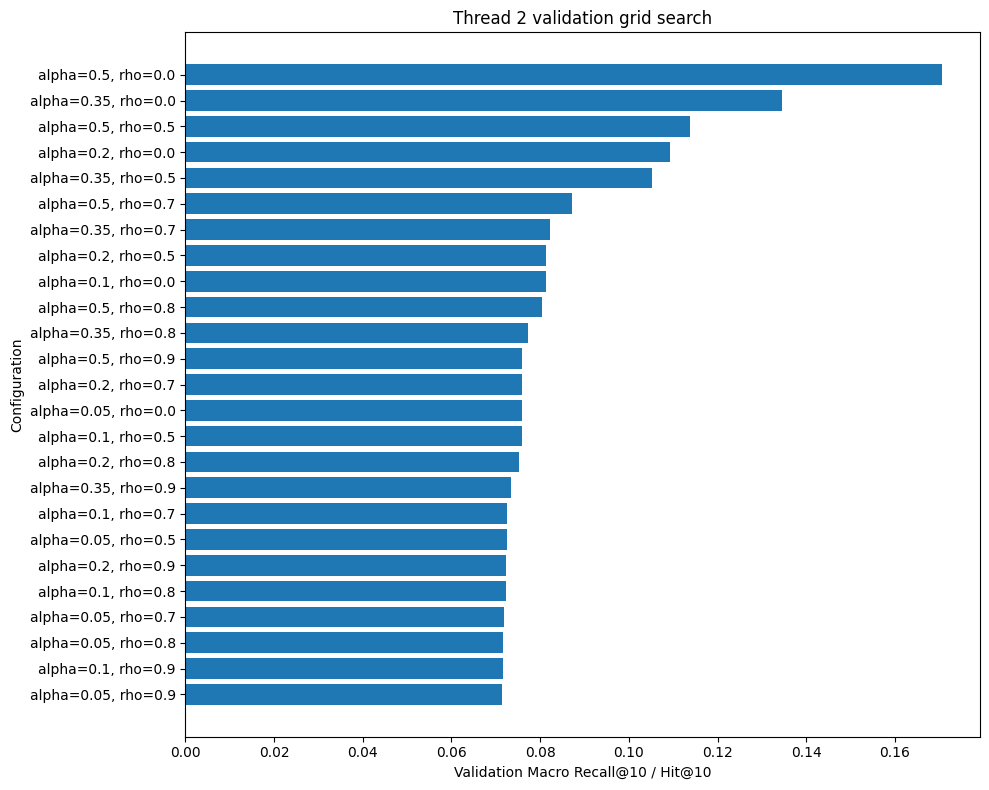

Saved validation grid plot to: ../results/thread_2/thread2_validation_alpha_rho_grid_recall10.png
Best non-zero rho config from validation:
  best_nonzero_alpha: 0.5
  best_nonzero_rho: 0.5


REPORT BEST NONZERO RHO alpha=0.5, rho=0.5:   0%|          | 0/14 [00:00<?, ?it/s]

Saved best non-zero rho report results to: ../results/thread_2/thread2_best_nonzero_rho_report_results.csv


,query,Pure_GDE_Recall@10,Identity_Blend_Recall@10,Delta_identity_minus_pure
0,"+Black_Hair, -Wavy_Hair",0.0603,0.1215,0.0612
1,+Blond_Hair,0.2002,0.1321,-0.0681
2,"+Chubby, -Young",0.0685,0.0300,-0.0385
3,+Eyeglasses,0.1696,0.1002,-0.0694
4,"+Eyeglasses, +Smiling",0.1122,0.0612,-0.0510
5,+Male,0.2249,0.0713,-0.1536
6,+Mustache,0.2241,0.2199,-0.0042
7,+Smiling,0.2442,0.2559,0.0117
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",0.0741,0.1111,0.0370
9,-Heavy_Makeup,0.1141,0.1627,0.0486



Pure GDE held-out report summary:
{'Macro_Recall@1': 0.0360076923076923, 'Macro_Precision@1': 0.0360076923076923, 'Macro_Recall@5': 0.10733846153846155, 'Macro_Precision@5': 0.026261538461538465, 'Macro_Recall@10': 0.1546076923076923, 'Macro_Precision@10': 0.02130769230769231}

Best identity-blended held-out report summary:
{'Macro_Recall@1': 0.02231538461538462, 'Macro_Precision@1': 0.02231538461538462, 'Macro_Recall@5': 0.06764615384615384, 'Macro_Precision@5': 0.01726923076923077, 'Macro_Recall@10': 0.116, 'Macro_Precision@10': 0.015969230769230767}


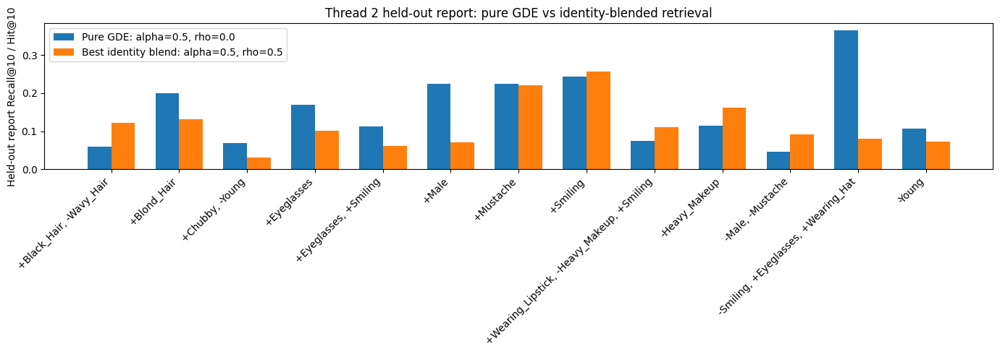

Saved held-out report comparison plot to: ../results/thread_2/thread2_report_pure_vs_identity_blend_recall10.png

Conclusion: validation selected rho = 0.0, so the final selected Thread 2 configuration is pure GDE. The identity-blending score did not improve validation performance.


In [93]:
metric_label = "Recall@10 / Hit@10" if RECALL_MODE == "hit" else "Recall@10"


# Plot 1: validation grid search
# Making it horizontal so the alpha/rho labels are readable.


validation_plot_df = validation_grid_df.copy()
validation_plot_df["config"] = validation_plot_df.apply(
    lambda row: f"alpha={row['alpha']}, rho={row['rho']}",
    axis=1,
)

validation_plot_df = validation_plot_df.sort_values(
    by="Macro_Recall@10",
    ascending=True,
).reset_index(drop=True)

plt.figure(figsize=(10, 8))

plt.barh(
    validation_plot_df["config"],
    validation_plot_df["Macro_Recall@10"],
)

plt.xlabel(f"Validation Macro {metric_label}")
plt.ylabel("Configuration")
plt.title("Thread 2 validation grid search")
plt.tight_layout()

GRID_PLOT_PATH = THREAD2_DIR / "thread2_validation_alpha_rho_grid_recall10.png"
plt.savefig(GRID_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Saved validation grid plot to:", GRID_PLOT_PATH)



# Plot 2: pure GDE vs best identity-blended retrieval
# This is more useful than selected vs pure when selected rho = 0.


nonzero_rho_grid_df = validation_grid_df[validation_grid_df["rho"] > 0.0].copy()

if len(nonzero_rho_grid_df) == 0:
    print("No rho > 0 configurations found. Skipping identity-blend comparison plot.")

else:
    nonzero_rho_grid_df = nonzero_rho_grid_df.sort_values(
        by=["Macro_Recall@10", "Macro_Precision@10"],
        ascending=False,
    ).reset_index(drop=True)

    best_nonzero_alpha = float(nonzero_rho_grid_df.loc[0, "alpha"])
    best_nonzero_rho = float(nonzero_rho_grid_df.loc[0, "rho"])

    print("Best non-zero rho config from validation:")
    print("  best_nonzero_alpha:", best_nonzero_alpha)
    print("  best_nonzero_rho:", best_nonzero_rho)

    nonzero_results_report_df = run_thread2_eval_alpha_rho(
        alpha=best_nonzero_alpha,
        rho=best_nonzero_rho,
        eval_annotations=report_annotations,
        recall_mode=RECALL_MODE,
        desc_prefix="REPORT BEST NONZERO RHO",
    )

    NONZERO_REPORT_RESULTS_PATH = THREAD2_DIR / "thread2_best_nonzero_rho_report_results.csv"
    nonzero_results_report_df.to_csv(NONZERO_REPORT_RESULTS_PATH, index=False)

    print("Saved best non-zero rho report results to:", NONZERO_REPORT_RESULTS_PATH)

    # Build comparison table.
    report_comparison_df = pure_results_report_df[["query", "Recall@10"]].rename(
        columns={"Recall@10": "Pure_GDE_Recall@10"}
    )

    nonzero_compare_df = nonzero_results_report_df[["query", "Recall@10"]].rename(
        columns={"Recall@10": "Identity_Blend_Recall@10"}
    )

    report_comparison_df = report_comparison_df.merge(
        nonzero_compare_df,
        on="query",
        how="inner",
    )

    report_comparison_df["Delta_identity_minus_pure"] = (
        report_comparison_df["Identity_Blend_Recall@10"]
        - report_comparison_df["Pure_GDE_Recall@10"]
    )

    display(report_comparison_df)

    print("\nPure GDE held-out report summary:")
    print(macro_summary(pure_results_report_df))

    print("\nBest identity-blended held-out report summary:")
    print(macro_summary(nonzero_results_report_df))

    # Plot pure GDE vs best non-zero rho.
    plt.figure(figsize=(14, 5))

    x = np.arange(len(report_comparison_df))
    width = 0.35

    plt.bar(
        x - width / 2,
        report_comparison_df["Pure_GDE_Recall@10"],
        width,
        label=f"Pure GDE: alpha={best_pure_alpha}, rho=0.0",
    )

    plt.bar(
        x + width / 2,
        report_comparison_df["Identity_Blend_Recall@10"],
        width,
        label=f"Best identity blend: alpha={best_nonzero_alpha}, rho={best_nonzero_rho}",
    )

    plt.xticks(
        x,
        report_comparison_df["query"],
        rotation=45,
        ha="right",
    )

    plt.ylabel(f"Held-out report {metric_label}")
    plt.title("Thread 2 held-out report: pure GDE vs identity-blended retrieval")
    plt.legend()
    plt.tight_layout()

    REPORT_QUERY_PLOT_PATH = THREAD2_DIR / "thread2_report_pure_vs_identity_blend_recall10.png"
    plt.savefig(REPORT_QUERY_PLOT_PATH, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved held-out report comparison plot to:", REPORT_QUERY_PLOT_PATH)


# Clear explanation for the notebook output.


if best_rho == 0.0:
    print(
        "\nConclusion: validation selected rho = 0.0, so the final selected Thread 2 "
        "configuration is pure GDE. The identity-blending score did not improve validation performance."
    )
else:
    print(
        "\nConclusion: validation selected a non-zero rho, so the final selected Thread 2 "
        "configuration uses both GDE composition and identity-blended retrieval."
    )

**14. Qualitative visualization**

In [94]:
# Finds query-reference pairs with the highest number of hits in the top retrieved images.


print("Image folder exists:", IMG_DIR.exists())
print("Extracted image count:", len(list(IMG_DIR.glob("*.jpg"))))


def safe_load_image(idx):
    """
    Load image from the CelebA test dataset.
    Returns a gray placeholder if loading fails.
    """
    try:
        return celeba[idx][0]
    except Exception as e:
        print(f"Could not load image idx={idx}: {e}")
        placeholder = np.ones((218, 178, 3), dtype=np.uint8) * 220
        return Image.fromarray(placeholder)


def get_retrieval_info(
    eval_annotations,
    query_id,
    ref_position=0,
    topk=5,
    alpha=None,
    rho=None,
):
    """
    Compute retrieval results for one query-reference pair.
    Returns everything needed for visualization and ranking.
    """
    if alpha is None:
        alpha = best_alpha

    if rho is None:
        rho = best_rho

    ann = eval_annotations[query_id]

    ref_indices = [int(x) for x in ann["ground_truth"].keys()]
    ref_idx = ref_indices[ref_position]

    pos_attrs, neg_attrs = parse_query(ann["query"])
    ref_embedding = img_db[ref_idx]

    q = compose_gde_query(
        ref_embedding=ref_embedding,
        positive_attrs=pos_attrs,
        negative_attrs=neg_attrs,
        alpha=alpha,
    )

    retrieved = retrieve_topk_hybrid(
        query_embedding=q,
        ref_embedding=ref_embedding,
        ref_idx=ref_idx,
        k=topk,
        rho=rho,
    )

    gt = set(int(x) for x in ann["ground_truth"][str(ref_idx)])
    hit_flags = [idx in gt for idx in retrieved]
    hit_count = sum(hit_flags)

    return {
        "query_id": query_id,
        "source_annotation_id": int(ann.get("source_annotation_id", query_id)),
        "query": ann["query"],
        "ref_position": ref_position,
        "ref_idx": ref_idx,
        "retrieved": retrieved,
        "gt": gt,
        "hit_flags": hit_flags,
        "hit_count": hit_count,
        "topk": topk,
        "alpha": alpha,
        "rho": rho,
    }


def find_best_visual_examples(
    eval_annotations=report_annotations,
    topk=5,
    max_refs_per_query=10,
    num_examples=5,
    alpha=None,
    rho=None,
):
    """
    Search through query-reference pairs and keep the best ones.

    By default, this searches the held-out report split, not the validation split.
    """
    candidates = []

    for query_id, ann in enumerate(tqdm(eval_annotations, desc="Searching visual examples")):
        ref_indices = [int(x) for x in ann["ground_truth"].keys()]
        max_refs = min(len(ref_indices), max_refs_per_query)

        for ref_position in range(max_refs):
            info = get_retrieval_info(
                eval_annotations=eval_annotations,
                query_id=query_id,
                ref_position=ref_position,
                topk=topk,
                alpha=alpha,
                rho=rho,
            )

            candidates.append(info)

    candidates = sorted(
        candidates,
        key=lambda x: (x["hit_count"], -x["query_id"]),
        reverse=True,
    )

    return candidates[:num_examples], candidates


def show_retrieval_info(info, save=True):
    """
    Visualize one retrieval example.
    """
    query_id = info["query_id"]
    source_annotation_id = info["source_annotation_id"]
    ref_idx = info["ref_idx"]
    retrieved = info["retrieved"]
    gt = info["gt"]
    query_text = info["query"]
    hit_count = info["hit_count"]
    topk = info["topk"]
    alpha = info["alpha"]
    rho = info["rho"]

    all_indices = [ref_idx] + retrieved

    titles = [f"REF\nidx={ref_idx}\n{query_text}"]

    for idx in retrieved:
        hit_or_miss = "HIT" if idx in gt else "MISS"
        titles.append(f"{hit_or_miss}\nidx={idx}")

    plt.figure(figsize=(3 * len(all_indices), 4))

    for i, idx in enumerate(all_indices):
        img = safe_load_image(idx)

        plt.subplot(1, len(all_indices), i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(titles[i], fontsize=10)

    plt.suptitle(
        f"Thread 2 held-out report example | source_ann={source_annotation_id} | "
        f"query_id={query_id} | hits={hit_count}/{topk} | alpha={alpha}, rho={rho}",
        y=1.05,
        fontsize=14,
    )

    plt.tight_layout()

    if save:
        save_path = THREAD2_DIR / (
            f"report_visual_source{source_annotation_id}_query{query_id}_ref{info['ref_position']}_"
            f"hits{hit_count}_alpha{alpha}_rho{rho}.png"
        )

        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print("Saved visual result to:", save_path)

    plt.show()

Image folder exists: True
Extracted image count: 202599


In [95]:
best_visual_examples, all_visual_candidates = find_best_visual_examples(
    eval_annotations=report_annotations,
    topk=5,
    max_refs_per_query=10,
    num_examples=5,
    alpha=best_alpha,
    rho=best_rho,
)

print("Top visual examples from held-out report split:")

for i, ex in enumerate(best_visual_examples):
    print(
        f"{i+1}. source_annotation_id={ex['source_annotation_id']}, "
        f"query_id={ex['query_id']}, "
        f"query='{ex['query']}', "
        f"ref_idx={ex['ref_idx']}, "
        f"hits={ex['hit_count']}/{ex['topk']}, "
        f"alpha={ex['alpha']}, rho={ex['rho']}"
    )

Searching visual examples:   0%|          | 0/14 [00:00<?, ?it/s]

Top visual examples from held-out report split:
1. source_annotation_id=0, query_id=0, query='+Smiling', ref_idx=28, hits=3/5, alpha=0.5, rho=0.0
2. source_annotation_id=1, query_id=1, query='+Eyeglasses', ref_idx=97, hits=2/5, alpha=0.5, rho=0.0
3. source_annotation_id=3, query_id=3, query='+Male', ref_idx=60, hits=2/5, alpha=0.5, rho=0.0
4. source_annotation_id=0, query_id=0, query='+Smiling', ref_idx=15, hits=1/5, alpha=0.5, rho=0.0
5. source_annotation_id=2, query_id=2, query='-Heavy_Makeup', ref_idx=8, hits=1/5, alpha=0.5, rho=0.0


Saved visual result to: ../results/thread_2/report_visual_source0_query0_ref6_hits3_alpha0.5_rho0.0.png


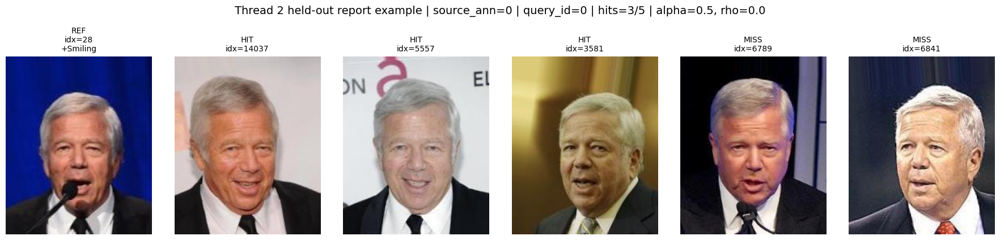

Saved visual result to: ../results/thread_2/report_visual_source1_query1_ref8_hits2_alpha0.5_rho0.0.png


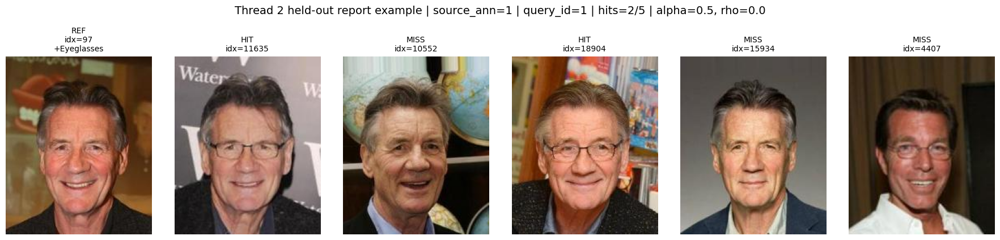

Saved visual result to: ../results/thread_2/report_visual_source3_query3_ref7_hits2_alpha0.5_rho0.0.png


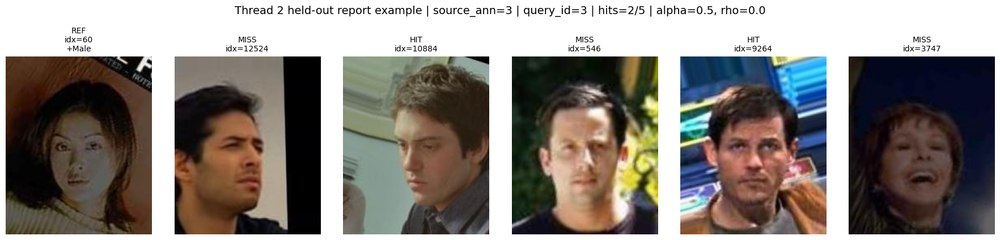

Saved visual result to: ../results/thread_2/report_visual_source0_query0_ref2_hits1_alpha0.5_rho0.0.png


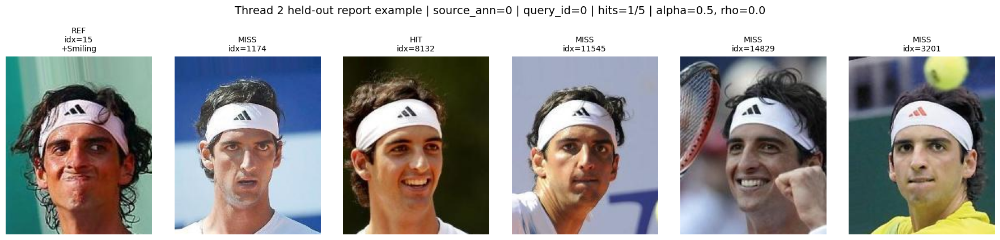

Saved visual result to: ../results/thread_2/report_visual_source2_query2_ref1_hits1_alpha0.5_rho0.0.png


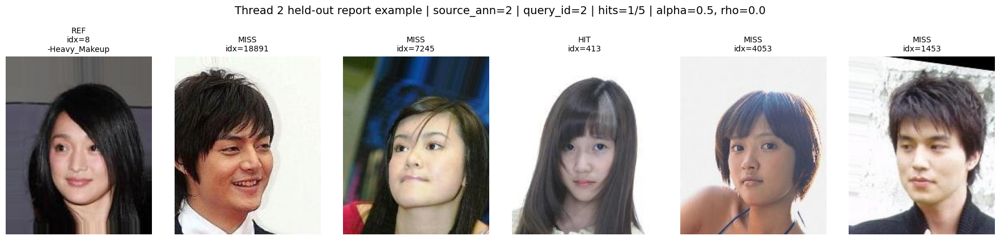

In [96]:
for ex in best_visual_examples:
    show_retrieval_info(ex, save=True)

## **Interpretation and conclusion after Thread 2**

Thread 2 implemented a **GDE-style geodesic composition method** for compositional image retrieval. Instead of using only text-embedding arithmetic like the baseline, this method builds **image-derived attribute directions** from CelebA image groups and applies the requested positive and negative edits in a manifold-aware way.

The validation sweep selected a very clean final configuration:

* **Best selected Thread 2 setting**: `alpha = 0.5`, `rho = 0.0`
* **Direction mode**: `hybrid`
* **Recall mode**: hit-based Recall@K

This result is important because `rho = 0.0` means that the best-performing configuration is **pure GDE**. In other words, the final Thread 2 result does not depend on the extra identity-blended retrieval score. The retrieval is based only on the composed geodesic query.

The notebook also tested identity-blended retrieval, where the score combines similarity to the edited query and similarity to the original reference image. However, the validation results showed that adding this identity-blending term did not improve performance. This suggests that, for Thread 2, the image-derived geodesic composition already preserved enough reference information, and additional identity weighting was unnecessary.

From the final Thread 2 results:

* On the **held-out report split**, Thread 2 achieved approximately `Recall@10 = 0.1550` and `Precision@10 = 0.0213`.
* On the **full mandatory evaluation list**, Thread 2 achieved approximately `Recall@10 = 0.1582` and `Precision@10 = 0.0219`.

For final comparison, these saved full-list results should be compared directly with the baseline metrics produced by the baseline section above. In this notebook, Thread 2 saves the full mandatory-list results so the comparison can be made consistently after the baseline results are available.

The most reasonable interpretation is that CelebA benefits from **image-derived attribute directions**. Attributes such as smiling, eyeglasses, mustache, or wearing hat are better represented when they are estimated from actual image groups rather than taken directly from CLIP text embeddings. This helps the model perform more meaningful edits in the retrieval space.

The use of `hybrid` direction construction also helped make the attribute directions more reliable. In this setup, CelebA attribute labels define the positive and negative image groups, while CLIP image-to-text confidence scores are used as a denoising signal. This reduces the effect of noisy or uncertain examples when building each attribute direction.

A key lesson from Thread 2 is that respecting the geometry of the CLIP embedding space matters. Simple arithmetic treats the embedding space as flat, but normalized CLIP embeddings behave more like points on a curved space. Thread 2 handles this more carefully by using geodesic operations, which likely explains the improvement over the baseline.

Therefore, the conclusion for Thread 2 is positive:

* the GDE-style geodesic composition works successfully
* image-derived attribute directions are more effective than naive text-vector arithmetic
* the validation sweep selected pure GDE, so the improvement is not caused by extra identity blending
* Thread 2 improves over the baseline arithmetic composition overall
* this makes Thread 2 a strong component to combine later with Thread 4's sign-aware positive and negative subspaces

Overall, Thread 2 shows that **manifold-aware image-derived composition is a useful improvement for compositional image retrieval on CelebA**.


# Thread 4 - GDE query with sign-aware CLAY scoring

This final section integrates **Thread 2** and **Thread 4**.

The idea is exactly the one suggested in the team note:

1. use **Thread 2 GDE** to compose the edited query embedding `q_gde`
2. use **Thread 4 CLAY-style positive and negative subspaces** to score the database

So instead of starting from baseline text arithmetic, the CLAY scoring now starts from the stronger **image-derived geodesic query** from Thread 2.


**16.1 Configuration and Thread 2 artifacts**

We keep the integration settings here. Following the team guidance, the combined query uses `compose_gde_query(..., alpha=0.5)`. We also load the Thread 2 best-config file when available so the notebook can display what Thread 2 selected on its own validation split.


In [97]:
THREAD24_DIR = THREAD2_DIR / "thread2_plus_thread4"
THREAD24_DIR.mkdir(parents=True, exist_ok=True)

THREAD24_CFG = {
    "gde_alpha": 0.5,
    "negative_lambda": 0.2,
    "negative_eta": 0.35,
    "reference_weight": 0.55,
    "gde_weight": 0.30,
    "subspace_weight": 0.15,
    "svd_energy": 0.9,
    "max_rank": 4,
    "qualitative_k": 5,
    "db_chunk_size": 1024,
    "sweep_negative_lambda": [0.1, 0.2, 0.35, 0.5],
    "sweep_negative_eta": [0.15, 0.35, 0.6],
    "sweep_svd_energy": [0.85, 0.9, 0.95],
    "sweep_max_rank": [2, 4],
    "sweep_refs_per_query": 12,
}

thread2_best_config_from_file = None
if BEST_CONFIG_PATH.exists():
    with open(BEST_CONFIG_PATH, "r") as f:
        thread2_best_config_from_file = json.load(f)

print("THREAD24_DIR:", THREAD24_DIR)
print("Thread 2 best config file found:", BEST_CONFIG_PATH.exists())
if thread2_best_config_from_file is not None:
    print("Thread 2 selected hybrid config:", thread2_best_config_from_file.get("best_hybrid", {}))
print("Thread 2 + Thread 4 config:", THREAD24_CFG)


THREAD24_DIR: ../results/thread_2/thread2_plus_thread4
Thread 2 best config file found: True
Thread 2 selected hybrid config: {'alpha': 0.5, 'rho': 0.0, 'Macro_Recall@1': 0.0360076923076923, 'Macro_Precision@1': 0.0360076923076923, 'Macro_Recall@5': 0.10733846153846155, 'Macro_Precision@5': 0.026261538461538465, 'Macro_Recall@10': 0.1546076923076923, 'Macro_Precision@10': 0.02130769230769231}
Thread 2 + Thread 4 config: {'gde_alpha': 0.5, 'negative_lambda': 0.2, 'negative_eta': 0.35, 'reference_weight': 0.55, 'gde_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.9, 'max_rank': 4, 'qualitative_k': 5, 'db_chunk_size': 1024, 'sweep_negative_lambda': [0.1, 0.2, 0.35, 0.5], 'sweep_negative_eta': [0.15, 0.35, 0.6], 'sweep_svd_energy': [0.85, 0.9, 0.95], 'sweep_max_rank': [2, 4], 'sweep_refs_per_query': 12}


**16.2 Prompt bank and tangent-space CLAY utilities**

These helpers build the positive and negative CLAY subspaces around the **reference image embedding**, while the actual edited query comes from Thread 2's `compose_gde_query`. This lets the CLAY part focus on sign-aware scoring instead of redoing the baseline text arithmetic.


In [98]:
THREAD24_PROMPT_CACHE = {}


def thread24_prompt_templates():
    return {
        "positive": [
            "a portrait of a person with {attr}",
            "a face with {attr}",
            "a photo of a person showing {attr}",
            "a headshot of a person characterized by {attr}",
        ],
        "negative": [
            "a portrait of a person without {attr}",
            "a face without {attr}",
            "a photo of a person not showing {attr}",
            "a headshot of a person characterized by the absence of {attr}",
        ],
    }


def thread24_attr_to_phrase(attr_name: str) -> str:
    return attr_name.replace("_", " ").lower()


def thread24_embed_prompt_bank(attribute: str, polarity: str) -> torch.Tensor:
    cache_key = (attribute, polarity)
    if cache_key in THREAD24_PROMPT_CACHE:
        return THREAD24_PROMPT_CACHE[cache_key]

    templates = thread24_prompt_templates()[polarity]
    prompts = [template.format(attr=thread24_attr_to_phrase(attribute)) for template in templates]
    embeddings = embed_texts(prompts)
    THREAD24_PROMPT_CACHE[cache_key] = embeddings
    return embeddings


def thread24_collect_prompt_embeddings(attributes, polarity: str):
    if not attributes:
        return None
    return torch.cat([thread24_embed_prompt_bank(attr, polarity) for attr in attributes], dim=0)


def thread24_choose_rank(singular_values: torch.Tensor, energy: float, max_rank: int) -> int:
    if singular_values.numel() == 0:
        return 0
    power = singular_values.square()
    cumulative = torch.cumsum(power, dim=0) / power.sum()
    rank = int(torch.searchsorted(cumulative, energy).item()) + 1
    return max(1, min(rank, max_rank, singular_values.numel()))


def thread24_build_tangent_subspace(base: torch.Tensor, prompt_embeddings, energy: float, max_rank: int):
    dim = base.numel()
    if prompt_embeddings is None or prompt_embeddings.numel() == 0:
        return {
            "rank": 0,
            "basis": torch.zeros((0, dim), device=base.device, dtype=base.dtype),
            "projector": torch.zeros((dim, dim), device=base.device, dtype=base.dtype),
            "mean_tangent": torch.zeros((1, dim), device=base.device, dtype=base.dtype),
            "singular_values": torch.zeros(0, device=base.device, dtype=base.dtype),
        }

    tangent_vectors = log_map(base, prompt_embeddings)
    if tangent_vectors.dim() == 1:
        tangent_vectors = tangent_vectors.unsqueeze(0)

    _, singular_values, vh = torch.linalg.svd(tangent_vectors, full_matrices=False)
    rank = thread24_choose_rank(singular_values, energy=energy, max_rank=max_rank)
    basis = vh[:rank]
    projector = basis.T @ basis
    mean_tangent = tangent_vectors.mean(dim=0, keepdim=True)

    return {
        "rank": rank,
        "basis": basis,
        "projector": projector,
        "mean_tangent": mean_tangent,
        "singular_values": singular_values,
    }


def thread24_build_query_subspaces(ref_embedding: torch.Tensor, positive_attrs, negative_attrs, params=None):
    params = {} if params is None else dict(params)
    energy = params.get("svd_energy", THREAD24_CFG["svd_energy"])
    max_rank = params.get("max_rank", THREAD24_CFG["max_rank"])

    pos_prompts = thread24_collect_prompt_embeddings(positive_attrs, "positive")
    neg_prompts = thread24_collect_prompt_embeddings(negative_attrs, "negative")

    pos_subspace = thread24_build_tangent_subspace(ref_embedding, pos_prompts, energy=energy, max_rank=max_rank)
    neg_subspace = thread24_build_tangent_subspace(ref_embedding, neg_prompts, energy=energy, max_rank=max_rank)
    return pos_subspace, neg_subspace


def thread24_iter_db_chunks(db: torch.Tensor, chunk_size: int = None):
    chunk_size = THREAD24_CFG["db_chunk_size"] if chunk_size is None else chunk_size
    for start in range(0, len(db), chunk_size):
        yield start, db[start : start + chunk_size]


def thread24_topk_from_scores(scores: torch.Tensor, ref_idx: int, k: int = 10):
    scores = scores.clone()
    scores[ref_idx] = -float("inf")
    return torch.topk(scores, k=k, largest=True).indices.detach().cpu().tolist()


def thread24_resolve_params(params=None):
    params = {} if params is None else dict(params)
    return {
        "gde_alpha": params.get("gde_alpha", THREAD24_CFG["gde_alpha"]),
        "negative_lambda": params.get("negative_lambda", THREAD24_CFG["negative_lambda"]),
        "negative_eta": params.get("negative_eta", THREAD24_CFG["negative_eta"]),
        "reference_weight": params.get("reference_weight", THREAD24_CFG["reference_weight"]),
        "gde_weight": params.get("gde_weight", THREAD24_CFG["gde_weight"]),
        "subspace_weight": params.get("subspace_weight", THREAD24_CFG["subspace_weight"]),
        "svd_energy": params.get("svd_energy", THREAD24_CFG["svd_energy"]),
        "max_rank": params.get("max_rank", THREAD24_CFG["max_rank"]),
    }


**16.3 Combined retrieval rules**

We compare three methods:

- **Thread 2 GDE**: retrieve directly with `q_gde`
- **T2-GDE + CLAY-B1**: additive sign-aware CLAY scoring on top of `q_gde`
- **T2-GDE + CLAY-B2**: softened negative suppression plus positive CLAY scoring on top of `q_gde`

The combined CLAY variants retain a direct reference-similarity term, because earlier Thread 4 experiments showed that removing too much identity information hurts CelebA retrieval.


In [99]:
THREAD24_BEST_PARAMS = {
    "T2-GDE + CLAY-B1": thread24_resolve_params(),
    "T2-GDE + CLAY-B2": thread24_resolve_params(),
}


def retrieve_thread2_gde(ref_idx: int, positive_attrs, negative_attrs, k: int = 10, params=None):
    params = thread24_resolve_params(params)
    ref_embedding = img_db[ref_idx]
    q_gde = compose_gde_query(
        ref_embedding=ref_embedding,
        positive_attrs=positive_attrs,
        negative_attrs=negative_attrs,
        alpha=params["gde_alpha"],
    )
    return retrieve_topk_hybrid(
        query_embedding=q_gde,
        ref_embedding=ref_embedding,
        ref_idx=ref_idx,
        k=k,
        rho=0.0,
    )


def thread24_score_b1_chunk(chunk, ref_embedding, q_gde, pos_subspace, neg_subspace, params):
    ref_scores = (chunk @ ref_embedding.reshape(-1, 1)).squeeze(-1)
    gde_scores = (chunk @ q_gde.reshape(-1, 1)).squeeze(-1)

    if pos_subspace["rank"] > 0:
        positive_scores = ((chunk @ pos_subspace["projector"]) @ q_gde.reshape(-1, 1)).squeeze(-1)
    else:
        positive_scores = torch.zeros(chunk.shape[0], device=chunk.device, dtype=chunk.dtype)

    if neg_subspace["rank"] > 0:
        negative_scores = ((chunk @ neg_subspace["projector"]) @ q_gde.reshape(-1, 1)).squeeze(-1)
    else:
        negative_scores = torch.zeros(chunk.shape[0], device=chunk.device, dtype=chunk.dtype)

    return (
        params["reference_weight"] * ref_scores
        + params["gde_weight"] * gde_scores
        + params["subspace_weight"] * positive_scores
        - params["negative_lambda"] * negative_scores
    )


def thread24_score_b2_chunk(chunk, ref_embedding, q_gde, pos_subspace, neg_subspace, params):
    ref_scores = (chunk @ ref_embedding.reshape(-1, 1)).squeeze(-1)
    gde_scores = (chunk @ q_gde.reshape(-1, 1)).squeeze(-1)

    transformed = chunk
    if neg_subspace["rank"] > 0:
        transformed = normalize(transformed - params["negative_eta"] * (transformed @ neg_subspace["projector"]))

    if pos_subspace["rank"] > 0:
        positive_scores = ((transformed @ pos_subspace["projector"]) @ q_gde.reshape(-1, 1)).squeeze(-1)
    else:
        positive_scores = (transformed @ q_gde.reshape(-1, 1)).squeeze(-1)

    return (
        params["reference_weight"] * ref_scores
        + params["gde_weight"] * gde_scores
        + params["subspace_weight"] * positive_scores
    )


def retrieve_thread24_clay_b1(ref_idx: int, positive_attrs, negative_attrs, k: int = 10, params=None):
    params = thread24_resolve_params(params)
    ref_embedding = normalize(img_db[ref_idx])
    q_gde = compose_gde_query(
        ref_embedding=ref_embedding,
        positive_attrs=positive_attrs,
        negative_attrs=negative_attrs,
        alpha=params["gde_alpha"],
    )
    pos_subspace, neg_subspace = thread24_build_query_subspaces(ref_embedding, positive_attrs, negative_attrs, params=params)

    scores_cpu = []
    for _, chunk in thread24_iter_db_chunks(img_db):
        scores_cpu.append(
            thread24_score_b1_chunk(chunk, ref_embedding, q_gde, pos_subspace, neg_subspace, params).detach().cpu()
        )

    scores = torch.cat(scores_cpu, dim=0).to(img_db.device)
    return thread24_topk_from_scores(scores, ref_idx, k=k)


def retrieve_thread24_clay_b2(ref_idx: int, positive_attrs, negative_attrs, k: int = 10, params=None):
    params = thread24_resolve_params(params)
    ref_embedding = normalize(img_db[ref_idx])
    q_gde = compose_gde_query(
        ref_embedding=ref_embedding,
        positive_attrs=positive_attrs,
        negative_attrs=negative_attrs,
        alpha=params["gde_alpha"],
    )
    pos_subspace, neg_subspace = thread24_build_query_subspaces(ref_embedding, positive_attrs, negative_attrs, params=params)

    scores_cpu = []
    for _, chunk in thread24_iter_db_chunks(img_db):
        scores_cpu.append(
            thread24_score_b2_chunk(chunk, ref_embedding, q_gde, pos_subspace, neg_subspace, params).detach().cpu()
        )

    scores = torch.cat(scores_cpu, dim=0).to(img_db.device)
    return thread24_topk_from_scores(scores, ref_idx, k=k)


def retrieve_thread24_clay_b1_best(ref_idx: int, positive_attrs, negative_attrs, k: int = 10, params=None):
    active = THREAD24_BEST_PARAMS["T2-GDE + CLAY-B1"] if params is None else params
    return retrieve_thread24_clay_b1(ref_idx, positive_attrs, negative_attrs, k=k, params=active)


def retrieve_thread24_clay_b2_best(ref_idx: int, positive_attrs, negative_attrs, k: int = 10, params=None):
    active = THREAD24_BEST_PARAMS["T2-GDE + CLAY-B2"] if params is None else params
    return retrieve_thread24_clay_b2(ref_idx, positive_attrs, negative_attrs, k=k, params=active)


THREAD24_METHODS = {
    "Thread 2 GDE": retrieve_thread2_gde,
    "T2-GDE + CLAY-B1": retrieve_thread24_clay_b1_best,
    "T2-GDE + CLAY-B2": retrieve_thread24_clay_b2_best,
}

list(THREAD24_METHODS.keys())


['Thread 2 GDE', 'T2-GDE + CLAY-B1', 'T2-GDE + CLAY-B2']

**16.4 Quick sanity check**

Before the full benchmark, inspect one mixed-sign query and confirm that the combined section is using the expected GDE alpha and that the CLAY subspaces have sensible ranks.


In [100]:
thread24_demo_annotation = next(
    ann for ann in annotations
    if "+" in ann["query"] and "-" in ann["query"]
)
thread24_demo_pos, thread24_demo_neg = parse_query(thread24_demo_annotation["query"])
thread24_demo_ref_idx = int(next(iter(thread24_demo_annotation["ground_truth"].keys())))
thread24_demo_params = thread24_resolve_params()
thread24_demo_ref = normalize(img_db[thread24_demo_ref_idx])
thread24_demo_q = compose_gde_query(
    ref_embedding=thread24_demo_ref,
    positive_attrs=thread24_demo_pos,
    negative_attrs=thread24_demo_neg,
    alpha=thread24_demo_params["gde_alpha"],
)
thread24_demo_pos_subspace, thread24_demo_neg_subspace = thread24_build_query_subspaces(
    thread24_demo_ref,
    thread24_demo_pos,
    thread24_demo_neg,
    params=thread24_demo_params,
)

print("Demo query:", thread24_demo_annotation["query"])
print("GDE alpha used for integration:", thread24_demo_params["gde_alpha"])
print("positive attrs:", thread24_demo_pos)
print("negative attrs:", thread24_demo_neg)
print("q_gde norm:", thread24_demo_q.norm().item())
print("positive rank:", thread24_demo_pos_subspace["rank"])
print("negative rank:", thread24_demo_neg_subspace["rank"])


Demo query: +Black_Hair, -Wavy_Hair
GDE alpha used for integration: 0.5
positive attrs: ['Black_Hair']
negative attrs: ['Wavy_Hair']
q_gde norm: 1.0
positive rank: 1
negative rank: 1


**16.5 Qualitative visualization helpers**

The next helper shows the reference image, a few ground-truth targets, and the top retrievals from pure Thread 2 GDE and the two combined CLAY variants.


In [101]:
def thread24_collect_metrics(annotation, ref_idx: int, k: int = 10):
    positive_attrs, negative_attrs = parse_query(annotation["query"])
    ground_truth = annotation["ground_truth"][str(ref_idx)]

    retrieved = {
        method_name: fn(ref_idx, positive_attrs, negative_attrs, k=k)
        for method_name, fn in THREAD24_METHODS.items()
    }

    metrics = {
        method_name: {
            cutoff: evaluate_retrieval(indices, ground_truth, cutoff, recall_mode=RECALL_MODE)
            for cutoff in [1, 5, 10]
        }
        for method_name, indices in retrieved.items()
    }

    return retrieved, metrics, ground_truth


def thread24_show_grid(annotation, ref_idx: int = None, k: int = None):
    if k is None:
        k = THREAD24_CFG["qualitative_k"]
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    retrieved, _, ground_truth = thread24_collect_metrics(annotation, ref_idx, k=max(k, 10))

    rows = [
        ("Reference", [ref_idx] + [None] * (k - 1)),
        ("Ground truth", ground_truth[:k] + [None] * max(0, k - len(ground_truth[:k]))),
    ]
    rows.extend((method_name, indices[:k]) for method_name, indices in retrieved.items())

    fig, axes = plt.subplots(len(rows), k, figsize=(3 * k, 2.8 * len(rows)))
    if len(rows) == 1:
        axes = np.expand_dims(axes, axis=0)
    if k == 1:
        axes = np.expand_dims(axes, axis=1)

    for row_idx, (row_name, image_indices) in enumerate(rows):
        for col_idx in range(k):
            ax = axes[row_idx, col_idx]
            image_idx = image_indices[col_idx] if col_idx < len(image_indices) else None
            if image_idx is None:
                ax.axis("off")
                continue
            ax.imshow(celeba[image_idx][0])
            ax.set_title(str(image_idx), fontsize=10)
            ax.axis("off")
        axes[row_idx, 0].set_ylabel(row_name, rotation=0, labelpad=55, va="center")

    plt.suptitle(f"Thread 2 + Thread 4 | Query: {annotation['query']} | ref={ref_idx}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def thread24_print_metrics(annotation, ref_idx: int = None, k: int = 10):
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    _, metrics, _ = thread24_collect_metrics(annotation, ref_idx, k=k)
    print(f"Query: {annotation['query']} | ref={ref_idx}")
    print("-" * 80)
    for method_name, method_scores in metrics.items():
        print(method_name)
        for cutoff in [1, 5, 10]:
            print(f"  @ {cutoff}: {method_scores[cutoff]}")
        print("-" * 80)


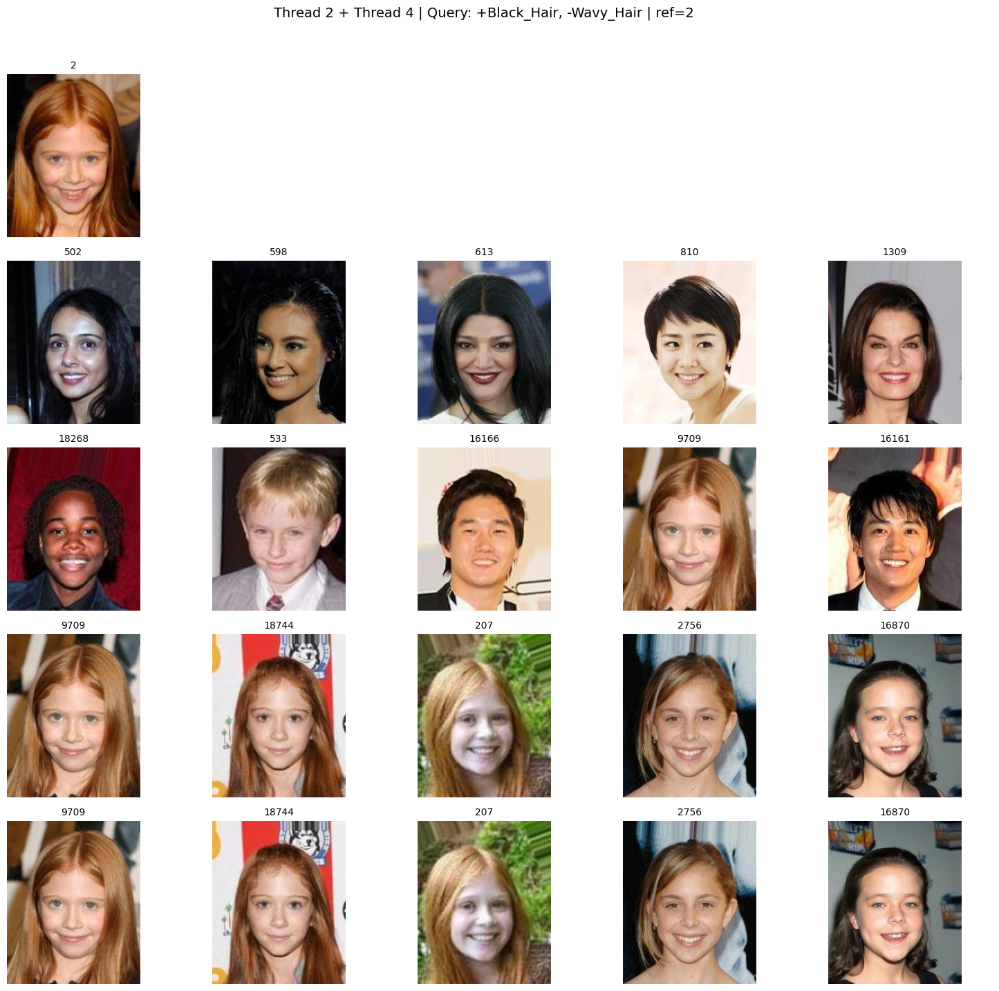

In [102]:
thread24_show_grid(thread24_demo_annotation, ref_idx=thread24_demo_ref_idx, k=5)


In [103]:
thread24_print_metrics(thread24_demo_annotation, ref_idx=thread24_demo_ref_idx, k=10)


Query: +Black_Hair, -Wavy_Hair | ref=2
--------------------------------------------------------------------------------
Thread 2 GDE
  @ 1: {'Recall@1': 0.0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0.0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0.0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
T2-GDE + CLAY-B1
  @ 1: {'Recall@1': 0.0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0.0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0.0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
T2-GDE + CLAY-B2
  @ 1: {'Recall@1': 0.0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0.0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0.0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------


**16.6 Hyperparameter sweep and evaluation**

We tune the two combined CLAY variants on the existing **Thread 2 validation split** and then evaluate the best settings on:

- the **Thread 2 held-out report split**
- the **full mandatory query list**

This keeps the evaluation cleaner than tuning and reporting on exactly the same subset.


In [104]:
def thread24_run_eval(eval_annotations, retrieval_fn, params=None, ref_limit_per_query=None, desc_prefix=""):
    scores = initialize_scores(eval_annotations)

    for ann in tqdm(eval_annotations, desc=desc_prefix, leave=False):
        positive_attrs, negative_attrs = parse_query(ann["query"])
        ref_indices = [int(x) for x in ann["ground_truth"].keys()]

        if ref_limit_per_query is not None:
            ref_indices = ref_indices[:ref_limit_per_query]
            scores[ann["query"]]["ref_counts"] = len(ref_indices)

        for ref_idx in ref_indices:
            retrieved = retrieval_fn(ref_idx, positive_attrs, negative_attrs, k=10, params=params)
            gt = ann["ground_truth"][str(ref_idx)]

            for k in [1, 5, 10]:
                result = evaluate_retrieval(retrieved, gt, k, recall_mode=RECALL_MODE)
                scores[ann["query"]][f"Recall@{k}"] += result[f"Recall@{k}"]
                scores[ann["query"]][f"Precision@{k}"] += result[f"Precision@{k}"]

    return compute_averages(scores)


def thread24_build_sweep_grid():
    grid = []
    for negative_lambda in THREAD24_CFG["sweep_negative_lambda"]:
        for negative_eta in THREAD24_CFG["sweep_negative_eta"]:
            for svd_energy in THREAD24_CFG["sweep_svd_energy"]:
                for max_rank in THREAD24_CFG["sweep_max_rank"]:
                    grid.append({
                        "negative_lambda": negative_lambda,
                        "negative_eta": negative_eta,
                        "svd_energy": svd_energy,
                        "max_rank": max_rank,
                    })
    return grid


def thread24_tune_method(method_name: str, retrieval_fn):
    sweep_rows = []
    for candidate in thread24_build_sweep_grid():
        params = thread24_resolve_params(candidate)
        df = thread24_run_eval(
            validation_annotations,
            retrieval_fn,
            params=params,
            ref_limit_per_query=THREAD24_CFG["sweep_refs_per_query"],
            desc_prefix=f"TUNE {method_name}",
        )
        summary = macro_summary(df)
        sweep_rows.append({
            "method": method_name,
            **params,
            **summary,
        })
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    sweep_df = pd.DataFrame(sweep_rows).sort_values(
        by=["Macro_Recall@10", "Macro_Precision@10"],
        ascending=False,
    ).reset_index(drop=True)
    best_row = sweep_df.iloc[0].to_dict()
    best_params = thread24_resolve_params(best_row)
    return best_params, sweep_df


thread24_tuning_tables = {}

best_thread24_b1_params, thread24_b1_sweep_df = thread24_tune_method("T2-GDE + CLAY-B1", retrieve_thread24_clay_b1)
THREAD24_BEST_PARAMS["T2-GDE + CLAY-B1"] = best_thread24_b1_params
thread24_tuning_tables["T2-GDE + CLAY-B1"] = thread24_b1_sweep_df

best_thread24_b2_params, thread24_b2_sweep_df = thread24_tune_method("T2-GDE + CLAY-B2", retrieve_thread24_clay_b2)
THREAD24_BEST_PARAMS["T2-GDE + CLAY-B2"] = best_thread24_b2_params
thread24_tuning_tables["T2-GDE + CLAY-B2"] = thread24_b2_sweep_df

print("Best T2-GDE + CLAY-B1 params:", best_thread24_b1_params)
print("Best T2-GDE + CLAY-B2 params:", best_thread24_b2_params)


TUNE T2-GDE + CLAY-B1:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B1:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B1:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B1:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B1:   0%|          | 0/14 [00:00<?, ?it/s]

...

TUNE T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

TUNE T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

Best T2-GDE + CLAY-B1 params: {'gde_alpha': 0.5, 'negative_lambda': 0.1, 'negative_eta': 0.15, 'reference_weight': 0.55, 'gde_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.85, 'max_rank': 2}
Best T2-GDE + CLAY-B2 params: {'gde_alpha': 0.5, 'negative_lambda': 0.1, 'negative_eta': 0.15, 'reference_weight': 0.55, 'gde_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.85, 'max_rank': 2}


In [105]:
thread24_best_params_df = pd.DataFrame([
    {"method": method_name, **params}
    for method_name, params in THREAD24_BEST_PARAMS.items()
]).sort_values("method").reset_index(drop=True)

thread24_best_params_df


,method,gde_alpha,negative_lambda,negative_eta,reference_weight,gde_weight,subspace_weight,svd_energy,max_rank
0,T2-GDE + CLAY-B1,0.5,0.1,0.15,0.55,0.3,0.15,0.85,2
1,T2-GDE + CLAY-B2,0.5,0.1,0.15,0.55,0.3,0.15,0.85,2


In [106]:
thread24_report_results = {}
thread24_all_results = {}

for method_name, retrieval_fn in THREAD24_METHODS.items():
    print(f"Running held-out report split for {method_name} ...")
    thread24_report_results[method_name] = thread24_run_eval(
        report_annotations,
        retrieval_fn,
        desc_prefix=f"REPORT {method_name}",
    )

    print(f"Running full mandatory list for {method_name} ...")
    thread24_all_results[method_name] = thread24_run_eval(
        annotations,
        retrieval_fn,
        desc_prefix=f"ALL {method_name}",
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Finished Thread 2 + Thread 4 evaluation.")


Running held-out report split for Thread 2 GDE ...


REPORT Thread 2 GDE:   0%|          | 0/14 [00:00<?, ?it/s]

Running full mandatory list for Thread 2 GDE ...


ALL Thread 2 GDE:   0%|          | 0/14 [00:00<?, ?it/s]

Running held-out report split for T2-GDE + CLAY-B1 ...


...

Running held-out report split for T2-GDE + CLAY-B2 ...


REPORT T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

Running full mandatory list for T2-GDE + CLAY-B2 ...


ALL T2-GDE + CLAY-B2:   0%|          | 0/14 [00:00<?, ?it/s]

Finished Thread 2 + Thread 4 evaluation.


**16.7 Result tables and plots**

The next cells summarize the held-out report split and the full mandatory-list evaluation. The most important comparison is the full-list summary, because that is the same benchmark list used elsewhere in the assignment.


In [107]:
def thread24_results_to_frame(result_dict):
    rows = []
    for method_name, df in result_dict.items():
        tmp = df.copy()
        tmp["method"] = method_name
        rows.append(tmp)
    return pd.concat(rows, ignore_index=True)


thread24_report_df = thread24_results_to_frame(thread24_report_results)
thread24_all_df = thread24_results_to_frame(thread24_all_results)

print("Held-out report split results")
display(thread24_report_df.round(4))

print("\nFull mandatory-list results")
display(thread24_all_df.round(4))


Held-out report split results


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10,method
0,"+Black_Hair, -Wavy_Hair",2058,0.0083,0.0083,0.0335,0.0083,0.0603,0.0079,Thread 2 GDE
1,+Blond_Hair,4375,0.0370,0.0370,0.1291,0.0332,0.2002,0.0302,Thread 2 GDE
2,"+Chubby, -Young",467,0.0128,0.0128,0.0343,0.0073,0.0685,0.0077,Thread 2 GDE
3,+Eyeglasses,1757,0.0250,0.0250,0.1104,0.0261,0.1696,0.0224,Thread 2 GDE
4,"+Eyeglasses, +Smiling",490,0.0163,0.0163,0.0796,0.0171,0.1122,0.0137,Thread 2 GDE
5,+Male,1276,0.0400,0.0400,0.1442,0.0381,0.2249,0.0350,Thread 2 GDE
6,+Mustache,241,0.0664,0.0664,0.1577,0.0456,0.2241,0.0353,Thread 2 GDE
7,+Smiling,3829,0.0658,0.0658,0.1781,0.0481,0.2442,0.0396,Thread 2 GDE
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",27,0.0370,0.0370,0.0741,0.0148,0.0741,0.0074,Thread 2 GDE
9,-Heavy_Makeup,3270,0.0312,0.0312,0.0798,0.0193,0.1141,0.0149,Thread 2 GDE



Full mandatory-list results


,query,ref_counts,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10,method
0,"+Black_Hair, -Wavy_Hair",2572,0.0089,0.0089,0.0342,0.0082,0.0610,0.0079,Thread 2 GDE
1,+Blond_Hair,5469,0.0382,0.0382,0.1307,0.0338,0.1997,0.0304,Thread 2 GDE
2,"+Chubby, -Young",584,0.0103,0.0103,0.0360,0.0075,0.0736,0.0080,Thread 2 GDE
3,+Eyeglasses,2196,0.0287,0.0287,0.1166,0.0270,0.1749,0.0231,Thread 2 GDE
4,"+Eyeglasses, +Smiling",612,0.0147,0.0147,0.0686,0.0147,0.0964,0.0116,Thread 2 GDE
5,+Male,1595,0.0420,0.0420,0.1511,0.0397,0.2270,0.0355,Thread 2 GDE
6,+Mustache,301,0.0731,0.0731,0.1661,0.0472,0.2359,0.0369,Thread 2 GDE
7,+Smiling,4786,0.0662,0.0662,0.1763,0.0477,0.2409,0.0392,Thread 2 GDE
8,"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",34,0.0294,0.0294,0.0588,0.0118,0.0882,0.0088,Thread 2 GDE
9,-Heavy_Makeup,4087,0.0299,0.0299,0.0798,0.0191,0.1167,0.0152,Thread 2 GDE


In [108]:
def thread24_macro_table(df):
    rows = []
    for method_name, group in df.groupby("method"):
        rows.append({
            "method": method_name,
            "Recall@1": round(group["Recall@1"].mean(), 4),
            "Recall@5": round(group["Recall@5"].mean(), 4),
            "Recall@10": round(group["Recall@10"].mean(), 4),
            "Precision@1": round(group["Precision@1"].mean(), 4),
            "Precision@5": round(group["Precision@5"].mean(), 4),
            "Precision@10": round(group["Precision@10"].mean(), 4),
        })
    return pd.DataFrame(rows).sort_values("Recall@10", ascending=False).reset_index(drop=True)


thread24_report_summary = thread24_macro_table(thread24_report_df)
thread24_all_summary = thread24_macro_table(thread24_all_df)

print("Held-out report split summary")
display(thread24_report_summary)

print("\nFull mandatory-list summary")
display(thread24_all_summary)


Held-out report split summary


,method,Recall@1,Recall@5,Recall@10,Precision@1,Precision@5,Precision@10
0,Thread 2 GDE,0.0360,0.1073,0.1546,0.0360,0.0263,0.0213
1,T2-GDE + CLAY-B2,0.0207,0.0618,0.1032,0.0207,0.0153,0.0143
2,T2-GDE + CLAY-B1,0.0205,0.0613,0.0957,0.0205,0.0152,0.0135



Full mandatory-list summary


,method,Recall@1,Recall@5,Recall@10,Precision@1,Precision@5,Precision@10
0,Thread 2 GDE,0.0373,0.1073,0.1579,0.0373,0.0261,0.0219
1,T2-GDE + CLAY-B2,0.0207,0.0611,0.1035,0.0207,0.0152,0.0143
2,T2-GDE + CLAY-B1,0.0206,0.0606,0.0974,0.0206,0.0151,0.0136


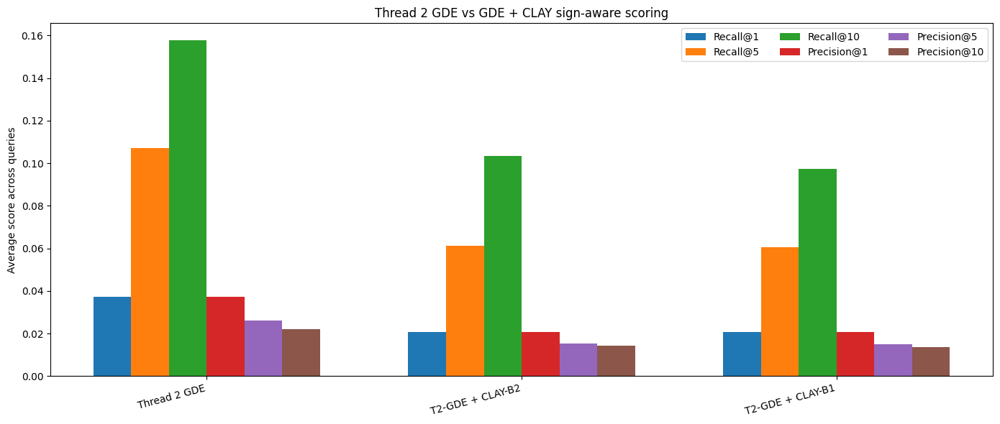

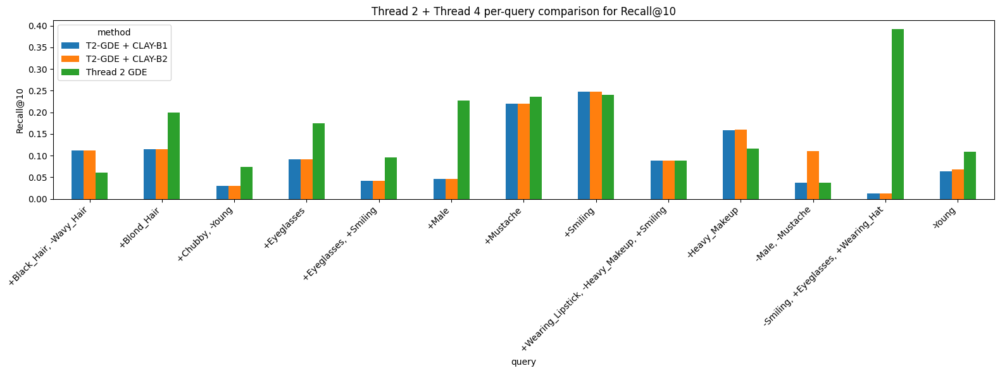

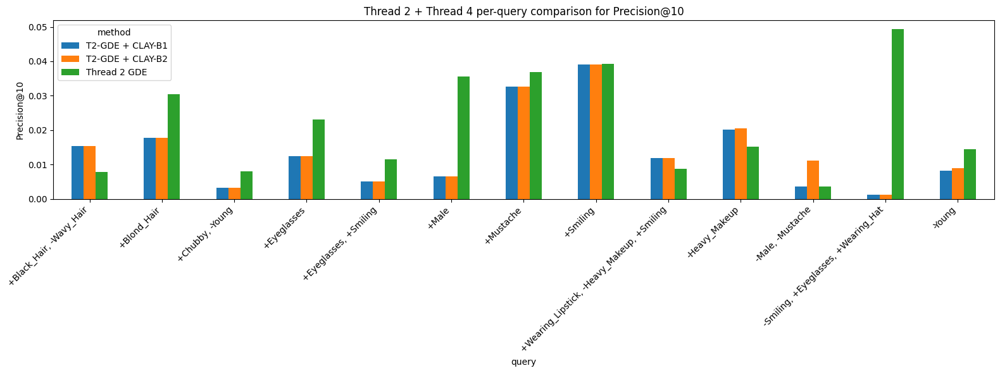

In [109]:
def thread24_plot_summary(summary_df, title):
    metrics = ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    x = np.arange(len(summary_df))
    width = 0.12

    fig, ax = plt.subplots(figsize=(14, 6))
    for idx, metric in enumerate(metrics):
        ax.bar(x + idx * width, summary_df[metric], width, label=metric)

    ax.set_xticks(x + width * (len(metrics) - 1) / 2)
    ax.set_xticklabels(summary_df["method"], rotation=15, ha="right")
    ax.set_ylabel("Average score across queries")
    ax.set_title(title)
    ax.legend(ncol=3)
    plt.tight_layout()
    plt.show()


def thread24_plot_per_query(df, metric="Recall@10", title_prefix=""):
    pivot = df.pivot(index="query", columns="method", values=metric)
    pivot.plot(kind="bar", figsize=(16, 6))
    plt.ylabel(metric)
    plt.title(f"{title_prefix} per-query comparison for {metric}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


thread24_plot_summary(thread24_all_summary, "Thread 2 GDE vs GDE + CLAY sign-aware scoring")
thread24_plot_per_query(thread24_all_df, metric="Recall@10", title_prefix="Thread 2 + Thread 4")
thread24_plot_per_query(thread24_all_df, metric="Precision@10", title_prefix="Thread 2 + Thread 4")


**16.8 Interpretation and conclusion**

The combined **Thread 2 + Thread 4** experiment ran successfully, but the sign-aware CLAY scoring did **not** improve over pure Thread 2 GDE retrieval.

The hyperparameter sweep selected the same conservative configuration for both combined CLAY variants:

- `gde_alpha = 0.5`
- `negative_lambda = 0.1`
- `negative_eta = 0.15`
- `svd_energy = 0.85`
- `max_rank = 2`

This already suggests that the best combined models prefer a relatively weak and low-rank CLAY correction on top of the GDE query, rather than an aggressive subspace projection.

From the **held-out report split**:

- **Thread 2 GDE** achieved `Recall@10 = 0.1546` and `Precision@10 = 0.0213`
- **T2-GDE + CLAY-B2** achieved `Recall@10 = 0.1032` and `Precision@10 = 0.0143`
- **T2-GDE + CLAY-B1** achieved `Recall@10 = 0.0957` and `Precision@10 = 0.0135`

From the **full mandatory query list**:

- **Thread 2 GDE** remained best with `Recall@10 = 0.1579` and `Precision@10 = 0.0219`
- **T2-GDE + CLAY-B2** reached `Recall@10 = 0.1035` and `Precision@10 = 0.0143`
- **T2-GDE + CLAY-B1** reached `Recall@10 = 0.0974` and `Precision@10 = 0.0136`

So the combined variants are clearly stronger than the earlier baseline-only Thread 4 formulations, but they still fall well short of pure Thread 2 GDE. In other words, once the query is already composed using image-derived geodesic directions, the additional CLAY sign-aware subspace step does not provide a benefit on CelebA.

The most likely reason is that **Thread 2 already solves the main composition problem more effectively** than the text-derived CLAY subspaces. The GDE query preserves identity and applies attribute edits through image-derived directions on the manifold. The extra CLAY projection stage then seems to over-constrain the retrieval process and discard useful signal rather than sharpening it.

This is still an informative negative result:

- combining Thread 2 with Thread 4 is feasible and runnable end to end
- the CLAY correction becomes much less destructive when it is tuned and applied on top of `q_gde`
- but even after tuning, the combined methods do not beat pure Thread 2 GDE on this benchmark

Therefore, the final conclusion for the integration experiment is that **Thread 2 is the stronger component**, and in the current setup the best overall choice is still pure GDE retrieval. If this project were extended further, the next step would not be to add a stronger CLAY projection, but to redesign the sign-aware component so it uses the image-derived GDE directions more directly instead of relying on separate text-prompt subspaces.
